# How Fast Does a Quantum Error-Correction Decoder Need to Be?

**Measuring Classical Feedback Latency in Software QEC Decoders, from Simulation to IBM Device Replicas**

*Swayam Shakya · Faculty of Science & Technology, Algoma University, Brampton, ON, Canada*

This notebook is the complete, runnable version of the project. It reruns every experiment, draws every figure,
re-checks each result with independent code, runs the full test suite, and confirms that the
[walkthrough page](index.html), the README and the [IEEE paper](paper/QEC_Research_Paper.pdf) all report the
same numbers as the data. Repository: <https://github.com/requiemdoomed/QEC-Latency-Decoder> [[1](#ref-1)].

**The question.** Quantum error correction only works if the loop *measure the syndrome → decode → apply the
correction* finishes before the qubits lose their state [[2](#ref-2), [3](#ref-3)]. Fault-tolerance theory assumes the
classical half of that loop keeps up [[4](#ref-4), [5](#ref-5)], and real-time decoding is now treated as a central
engineering problem [[6](#ref-6), [7](#ref-7)]. Simulations usually treat the decoder as free. Here I measure it, for
the smallest code that runs the whole loop: the three-qubit bit-flip code, whose decoder is a four-entry
look-up table [[8](#ref-8), [9](#ref-9)].

**How to run it.** On Linux, macOS or WSL with Python 3.11–3.13 and `gcc`:

```bash
bash setup.sh                         # makes qec-env/ with the pinned versions (incl. Jupyter)
source qec-env/bin/activate
jupyter lab QEC_Latency_Decoder.ipynb # or run it head-less:
jupyter nbconvert --to notebook --execute --inplace QEC_Latency_Decoder.ipynb
```

A full run takes about five minutes on two CPU cores. No IBM account is needed. Every result is written to
`outputs/notebook/`, so the committed `reference_results/` are never touched.

## Contents

0. [Setup and the audit log](#setup)
1. [Background](#background)
2. [Part 1: The physical layer](#part1)
3. [Part 2: The code and its decoder](#part2)
4. [Part 3: Decoder latency](#part3)
5. [Part 4: Calibrated IBM device replicas](#part4)
6. [Testing](#testing)
7. [Reproducibility and consistency audit](#audit)
8. [Audit summary](#summary)
9. [What it all means](#conclusions)
10. [References](#references)

Every part follows the same pattern: the question, the theory, the experiment (run through the same `src/`
modules that the walkthrough page displays), the figure, and then **checks**. Each check is written to an audit
log, and the summary in Section 8 stops the notebook with an error if any of them failed. Notebooks often do not
rerun cleanly [[10](#ref-10)], so this one is built to prove that it does, following the usual advice for shareable
notebooks: pinned dependencies, relative paths, seeded randomness and outputs kept separate from inputs
[[11](#ref-11), [12](#ref-12)].

<a id="setup"></a>
## 0. Setup and the audit log

The notebook expects to sit in the repository root, next to `src/`. Set `RERUN = False` to skip the simulations
and audit the committed reference results instead (useful for a quick look: under a minute instead of five).

In [1]:
RERUN = True        # False: copy reference_results/ instead of rerunning the experiments

import json, os, platform, re, shutil, subprocess, sys, time, html, zipfile, inspect, warnings
from pathlib import Path
from importlib import metadata

ROOT = Path.cwd()
while not (ROOT / 'src' / 'bit_flip_code.py').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Open this notebook from the repository root (the folder that holds src/).')
    ROOT = ROOT.parent
SRC, REF = ROOT / 'src', ROOT / 'reference_results'
OUT = ROOT / 'outputs' / 'notebook'
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC))
os.chdir(OUT)                    # the experiment scripts write their files into the working folder

import numpy as np
from scipy import stats
from IPython.display import display, Markdown, Image, Code
import matplotlib.pyplot as plt
print(f'Repository : {ROOT.name}/')
print(f'Outputs    : {OUT.relative_to(ROOT)}/')
print(f'Mode       : {"rerun every experiment" if RERUN else "audit the reference results only"}')

Repository : QEC-Latency-Decoder/
Outputs    : outputs/notebook/
Mode       : rerun every experiment


In [2]:
class Audit:
    """Every check in the notebook ends up here; Section 8 prints the table."""
    def __init__(self):
        self.rows = []
    def check(self, part, what, ok, detail=''):
        ok = bool(ok)
        self.rows.append((part, what, ok, str(detail)))
        print(f"{'PASS' if ok else 'FAIL'}  {what}" + (f'  ({detail})' if detail else ''))
        return ok

audit = Audit()

def show(png, width=900):
    """Display a PNG written by one of the experiment scripts (scaled down to keep the notebook small)."""
    from PIL import Image as PILImage
    import io
    im = PILImage.open(png).convert('RGB')
    if im.width > 1600:
        im = im.resize((1600, round(im.height * 1600 / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO(); im.save(buf, format='PNG', optimize=True)
    display(Image(data=buf.getvalue(), width=width))

def md_table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|' * len(header)]
    cell = lambda c: str(c).replace('|', '\\|')
    out += ['| ' + ' | '.join(cell(c) for c in r) + ' |' for r in rows]
    display(Markdown('\n'.join(out)))

def load(name, folder=None):
    with open((folder or OUT) / name) as fh:
        return json.load(fh)

def run_or_copy(fn, files):
    """Run an experiment, or (RERUN = False) copy its committed reference files instead."""
    t0 = time.perf_counter()
    if RERUN:
        fn()
    else:
        for f in files:
            shutil.copy(REF / f, OUT / f)
    print(f'[{time.perf_counter() - t0:.1f} s]')

**Environment.** The pinned versions in `requirements.txt` are part of the result: Aer's random streams and
SciPy's statistics can change between releases. This cell compares what is installed with the pins.

In [3]:
pins = {}
for line in (ROOT / 'requirements.txt').read_text().splitlines():
    line = line.split('#')[0].strip()
    if '==' in line:
        name, ver = line.split('==')
        pins[name.strip()] = ver.strip()
rows = []
for name, want in pins.items():
    have = metadata.version(name)
    rows.append((name, want, have, 'yes' if have == want else '**no**'))
md_table(['package', 'pinned', 'installed', 'match'], rows)
audit.check('Setup', 'installed packages match requirements.txt', all(r[3] == 'yes' for r in rows),
            f'{sum(r[3] == "yes" for r in rows)}/{len(rows)} pins')
audit.check('Setup', 'Python version is 3.11-3.13', (3, 11) <= sys.version_info[:2] <= (3, 13),
            platform.python_version())

| package | pinned | installed | match |
|---|---|---|---|
| qiskit | 2.5.2 | 2.5.2 | yes |
| qiskit-aer | 0.17.2 | 0.17.2 | yes |
| qiskit-ibm-runtime | 0.50.0 | 0.50.0 | yes |
| scipy | 1.17.1 | 1.17.1 | yes |
| numpy | 2.4.6 | 2.4.6 | yes |
| matplotlib | 3.11.2 | 3.11.2 | yes |
| statsmodels | 0.15.0 | 0.15.0 | yes |
| pylatexenc | 2.11 | 2.11 | yes |

PASS  installed packages match requirements.txt  (8/8 pins)
PASS  Python version is 3.11-3.13  (3.13.16)


True

**The C decoder.** `src/qec_decode.c` is compiled with every warning turned into an error, exactly as the
continuous-integration job does, and the experiment code is pointed at the result.

In [4]:
BUILD = ROOT / 'build'; BUILD.mkdir(exist_ok=True)
LIB = BUILD / 'qec_decode.so'
cc = subprocess.run(['gcc', '-O2', '-shared', '-fPIC', '-std=c11', '-Wall', '-Wextra', '-Werror',
                     '-o', str(LIB), str(SRC / 'qec_decode.c')], capture_output=True, text=True)
print(cc.stderr or 'gcc: no warnings')
os.environ['QEC_DECODE_LIB'] = str(LIB)
audit.check('Setup', 'C decoder compiles with -Wall -Wextra -Werror', cc.returncode == 0 and LIB.exists())

import qec_style
import experiment_1_1_coherence as exp11
import experiment_1_2_pauli_sensitivity as exp12
import bit_flip_code as bfc
import experiment_2_2_logical_error as exp22
import fit_distribution as fd
import experiment_3_jitter_profiler as exp3
import analysis_paper_ready as analysis
import experiment_4_real_hardware as exp4
qec_style.apply()
%matplotlib inline
env = exp3.environment()
md_table(['', ''], [(k, v) for k, v in env.items()])

gcc: no warnings
PASS  C decoder compiles with -Wall -Wextra -Werror


|  |  |
|---|---|
| python | 3.13.16 |
| platform | Linux-6.18.44-fc-v378-x86_64-with-glibc2.39 |
| machine | x86_64 |
| cpu_model | Intel(R) Xeon(R) Processor @ 2.10GHz |
| cpu_count | 2 |
| perf_counter_resolution_s | 1e-09 |
| perf_counter_implementation | clock_gettime(CLOCK_MONOTONIC) |

<a id="background"></a>
## 1. Background

### 1.1 The bit-flip code

The code stores one logical qubit in three physical ones [[8](#ref-8), [9](#ref-9)]:

$$|0_L\rangle = |000\rangle, \qquad |1_L\rangle = |111\rangle .$$

Two ancilla qubits measure the parities $Z_0Z_1$ and $Z_1Z_2$ without measuring the data itself, so a
superposition $\alpha|000\rangle + \beta|111\rangle$ survives the check. A single $X$ (bit-flip) error on
one data qubit gives a unique pair of parities, the **syndrome**, and the decoder is a table:

| syndrome (as Qiskit prints it) | meaning | correction |
|---|---|---|
| `00` | no error | none |
| `10` | qubit 0 flipped | $X_0$ |
| `11` | qubit 1 flipped | $X_1$ |
| `01` | qubit 2 flipped | $X_2$ |

Qiskit prints classical bits right to left, so the string reads $(Z_0Z_1)(Z_1Z_2)$. Getting this order wrong
silently "corrects" the wrong qubit, which is why the first check below tries every case.

If each data qubit flips independently with probability $p$, the code fails when two or three qubits flip:

$$P_L(p) = 3p^2(1-p) + p^3 = 3p^2 - 2p^3 . \tag{1}$$

For small $p$ this is quadratic, so the code helps whenever $p < 1/2$, and at $p = 1\%$ it should cut failures
about 33-fold.

### 1.2 The deadline

A qubit left idle dephases. In a Ramsey experiment (prepare $|+\rangle$, wait $t$, rotate back, measure) the
probability of reading 0 decays as

$$F(t) = \tfrac12 + \tfrac12\, e^{-t/T_2} . \tag{2}$$

With $T_2 = 120\ \mu s$, typical of current superconducting qubits [[3](#ref-3)], and $N = 3$ syndrome rounds per
logical cycle, I give each round the budget

$$\tau_{DD} = T_2 / N = 40\ \mu s . \tag{3}$$

This is a deliberately generous ceiling. Section 5 shows what waiting costs well before it is reached.

### 1.3 Measuring a deadline miss

For decode latencies $L_1, \dots, L_n$ the **violation rate** at deadline $\tau$ is

$$\mathrm{VR}(\tau) = P(L > \tau) \approx \frac1n \sum_{i=1}^{n} \mathbf 1[L_i > \tau] . \tag{4}$$

Misses are rare, so the interval matters more than the point estimate. I use the exact Clopper–Pearson interval
[[13](#ref-13), [14](#ref-14)]: with $k$ misses in $n$ cycles its 95% bounds are beta quantiles,
$\big[B(0.025;\,k,\,n-k+1),\; B(0.975;\,k+1,\,n-k)\big]$. With zero misses the upper bound is
$1 - 0.025^{1/n} \approx 3.689/n$, an honest "at most", where a bootstrap [[15](#ref-15)] would claim exactly zero.
The deadline at which 1% of cycles would miss is

$$\tau^* = \mathrm{VR}^{-1}(1\%) = P_{99}(L), \tag{5}$$

the 99th percentile, with a percentile-bootstrap interval. The other tools: Anderson–Darling tests whether
$\log L$ is normal [[16](#ref-16)], the Hill estimator measures how heavy the tail is [[17](#ref-17)],

$$\hat\alpha = \frac{k}{\sum_{i=1}^{k} \ln\big(X_{(i)}/X_{(k+1)}\big)} , \tag{6}$$

where $X_{(1)} \ge X_{(2)} \ge \dots$ are the sorted latencies and $k$ is 5% of $n$, and Python is compared with
C by the Mann–Whitney U test [[18](#ref-18)] with the rank-biserial effect size

$$r_{rb} = \frac{2U_1}{n_1 n_2} - 1 , \tag{7}$$

which is $+1$ when every Python cycle is slower than every C cycle. Success rates get Wilson intervals
[[19](#ref-19), [14](#ref-14)], protocols are compared with $\chi^2$ tests and pooled miss counts with Fisher's exact test
[[20](#ref-20)]. All of it uses SciPy, NumPy and statsmodels [[21](#ref-21), [22](#ref-22), [23](#ref-23)]; figures use Matplotlib
[[24](#ref-24)].

Why care about the slowest cycle and not the average? In large systems, rare slow events dominate the
experience of the whole system [[25](#ref-25)]. A decoder that is fast on average but occasionally stalls behaves the
same way.

### 1.4 The whole loop, and the circuit

The pipeline below is what the project measures; the circuit is the protected memory used on the IBM replicas
in Part 4. Real-time feed-forward (`if_test`) applies the correction while the qubits are still alive
[[26](#ref-26)].

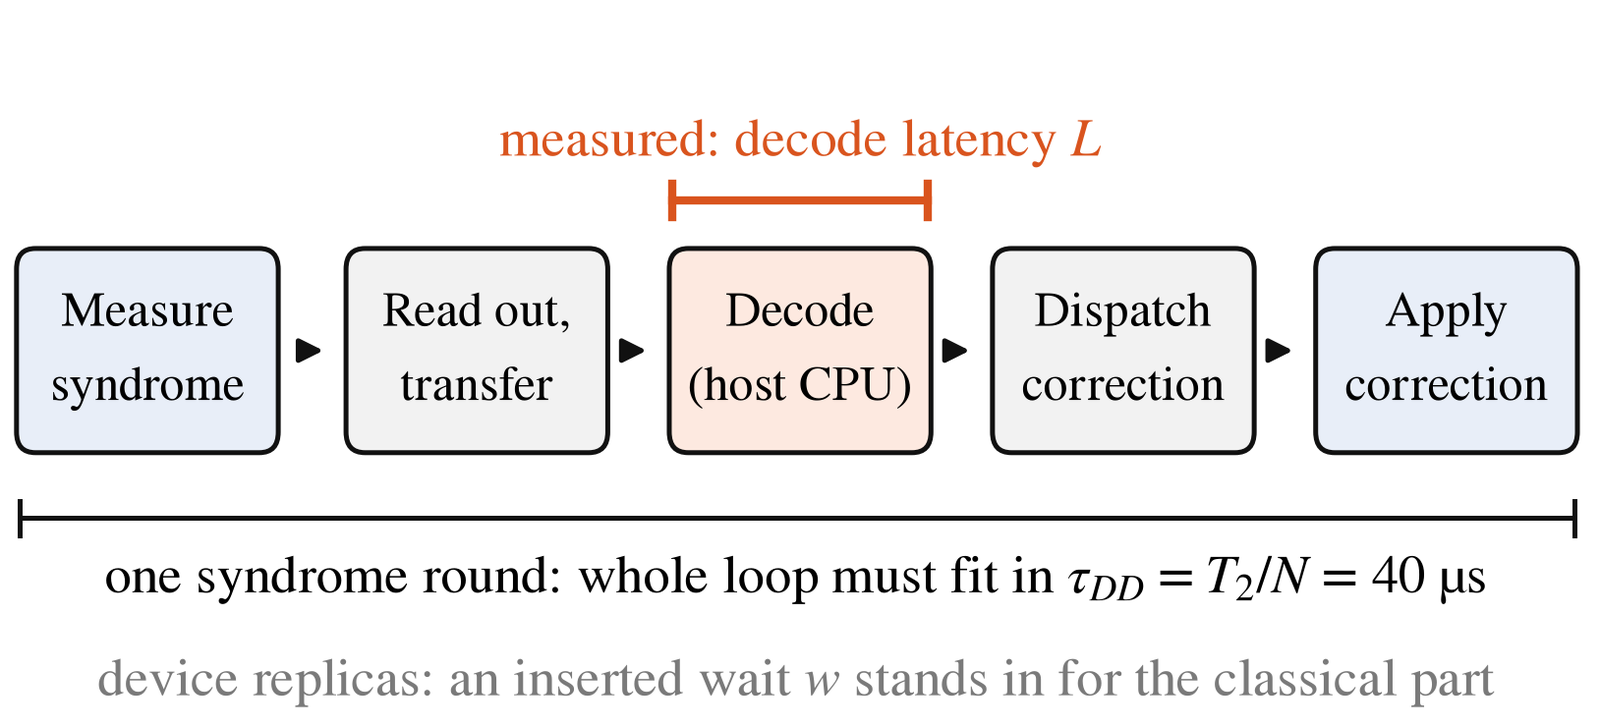

Saved: fig0_protected_circuit.png


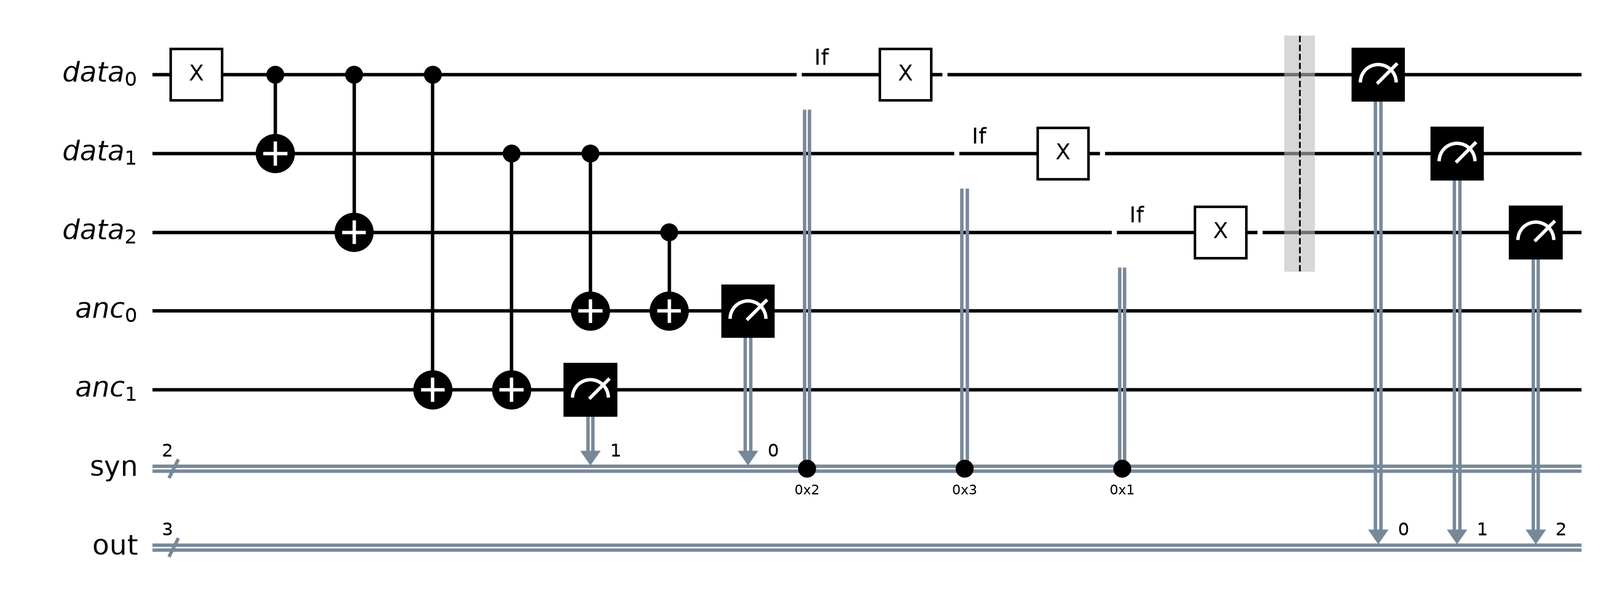

In [5]:
show(ROOT / 'paper' / 'figures' / 'fig1_pipeline.png', width=820)
exp4.draw_circuit()
show(OUT / 'fig0_protected_circuit.png', width=900)

**Check: every syndrome, both logical states.** Without noise the syndrome is deterministic, so this runs all
eight cases (two logical states × no error or one flip on each qubit) and confirms that the table points at the
flipped qubit. It also runs all three *double* flips: the code must get those wrong, because two flips look
exactly like one flip on the remaining qubit. That is the reason for the $3p^2$ term in Eq. (1).

In [6]:
from qiskit_aer import AerSimulator
code_ = bfc.BitFlipCode(seed=0)
ideal = AerSimulator(seed_simulator=1)

def syndrome_of(logical, flips):
    qc = code_.encode(logical)
    for q in flips:
        code_.inject_error(qc, q)
    qc = code_.syndrome_circuit(qc)
    counts = ideal.run(qc, shots=32).result().get_counts()
    assert len(counts) == 1, counts
    return next(iter(counts))

rows, single_ok, double_wrong = [], True, True
for logical in '01':
    for flips in [(), (0,), (1,), (2,)]:
        s = syndrome_of(logical, flips)
        corr = code_.decode_syndrome(s)
        ok = corr == (flips[0] if flips else None)
        single_ok &= ok
        rows.append((f'|{logical}_L⟩', flips or '—', s, corr, 'correct' if ok else 'WRONG'))
    for flips in [(0, 1), (0, 2), (1, 2)]:
        s = syndrome_of(logical, flips)
        corr = code_.decode_syndrome(s)
        after = set(flips) ^ ({corr} if corr is not None else set())
        double_wrong &= len(after) == 3                 # the "fix" completes a logical flip
        rows.append((f'|{logical}_L⟩', flips, s, corr, 'logical flip (expected)'))
md_table(['state', 'flipped', 'syndrome', 'decoder says', 'outcome'], rows)
audit.check('Background', 'LUT fixes every single flip, both logical states', single_ok, '8 cases')
audit.check('Background', 'every double flip turns into a logical error (distance 3)', double_wrong, '6 cases')

| state | flipped | syndrome | decoder says | outcome |
|---|---|---|---|---|
| \|0_L⟩ | — | 00 | None | correct |
| \|0_L⟩ | (0,) | 10 | 0 | correct |
| \|0_L⟩ | (1,) | 11 | 1 | correct |
| \|0_L⟩ | (2,) | 01 | 2 | correct |
| \|0_L⟩ | (0, 1) | 01 | 2 | logical flip (expected) |
| \|0_L⟩ | (0, 2) | 11 | 1 | logical flip (expected) |
| \|0_L⟩ | (1, 2) | 10 | 0 | logical flip (expected) |
| \|1_L⟩ | — | 00 | None | correct |
| \|1_L⟩ | (0,) | 10 | 0 | correct |
| \|1_L⟩ | (1,) | 11 | 1 | correct |
| \|1_L⟩ | (2,) | 01 | 2 | correct |
| \|1_L⟩ | (0, 1) | 01 | 2 | logical flip (expected) |
| \|1_L⟩ | (0, 2) | 11 | 1 | logical flip (expected) |
| \|1_L⟩ | (1, 2) | 10 | 0 | logical flip (expected) |

PASS  LUT fixes every single flip, both logical states  (8 cases)
PASS  every double flip turns into a logical error (distance 3)  (6 cases)


True

**Check: Eq. (1) from first principles.** Instead of trusting the algebra, enumerate all eight error patterns,
weight each by $p^{w}(1-p)^{3-w}$, decode it with the real table, and add up the failures.

In [7]:
from itertools import product

def p_logical_by_enumeration(p):
    total = 0.0
    for pattern in product([0, 1], repeat=3):            # which data qubits flipped
        w = sum(pattern)
        # parities as the circuit computes them: ancilla 1 = q0^q1, ancilla 0 = q1^q2; string = anc1 anc0
        syn = f'{pattern[0] ^ pattern[1]}{pattern[1] ^ pattern[2]}'
        fix = bfc.BitFlipCode.SYNDROME_TABLE[syn]
        final = list(pattern)
        if fix is not None:
            final[fix] ^= 1
        if sum(final) >= 2:                              # majority flipped: logical failure
            total += p**w * (1 - p)**(3 - w)
    return total

ps = np.array([0.001, 0.01, 0.05, 0.1, 0.3, 0.5])
enum = np.array([p_logical_by_enumeration(p) for p in ps])
closed = 3 * ps**2 - 2 * ps**3
md_table(['p', 'enumeration', '3p² − 2p³'], [(p, f'{a:.6g}', f'{b:.6g}') for p, a, b in zip(ps, enum, closed)])
audit.check('Background', 'enumerated P_L equals 3p^2 - 2p^3', np.allclose(enum, closed, rtol=0, atol=1e-15))
audit.check('Background', 'break-even at p = 1/2', abs(p_logical_by_enumeration(0.5) - 0.5) < 1e-15)

| p | enumeration | 3p² − 2p³ |
|---|---|---|
| 0.001 | 2.998e-06 | 2.998e-06 |
| 0.01 | 0.000298 | 0.000298 |
| 0.05 | 0.00725 | 0.00725 |
| 0.1 | 0.028 | 0.028 |
| 0.3 | 0.216 | 0.216 |
| 0.5 | 0.5 | 0.5 |

PASS  enumerated P_L equals 3p^2 - 2p^3
PASS  break-even at p = 1/2


True

<a id="part1"></a>
## 2. Part 1: The physical layer

**Question.** How fast does a qubit dephase, and which errors can a superposition feel?

**Design.** One qubit in Aer with thermal relaxation ($T_1 = 250\ \mu s$, $T_2 = 120\ \mu s$) attached to
50 ns idle gates. A Ramsey sequence from $|+\rangle$ idles for 0–300 µs in 25 steps, 4,096 shots each, every
point with its own seed. Eq. (2) is then fitted to the data.

def ramsey_circuit(depth: int) -> QuantumCircuit:
    qc = QuantumCircuit(1, 1)
    qc.h(0)
    for _ in range(depth):
        qc.id(0)
    qc.h(0)
    qc.measure(0, 0)
    return qc

Fitted T2          : 121.5 ± 1.3 µs  (model input 120.0 µs)
Deadline τ_DD      : 40 µs  (T2 / 3)
Fidelity at τ_DD   : 0.860


Saved: fig1_coherence_decay.pdf / fig1_coherence_decay.png
Saved: w1_coherence.json
[2.3 s]


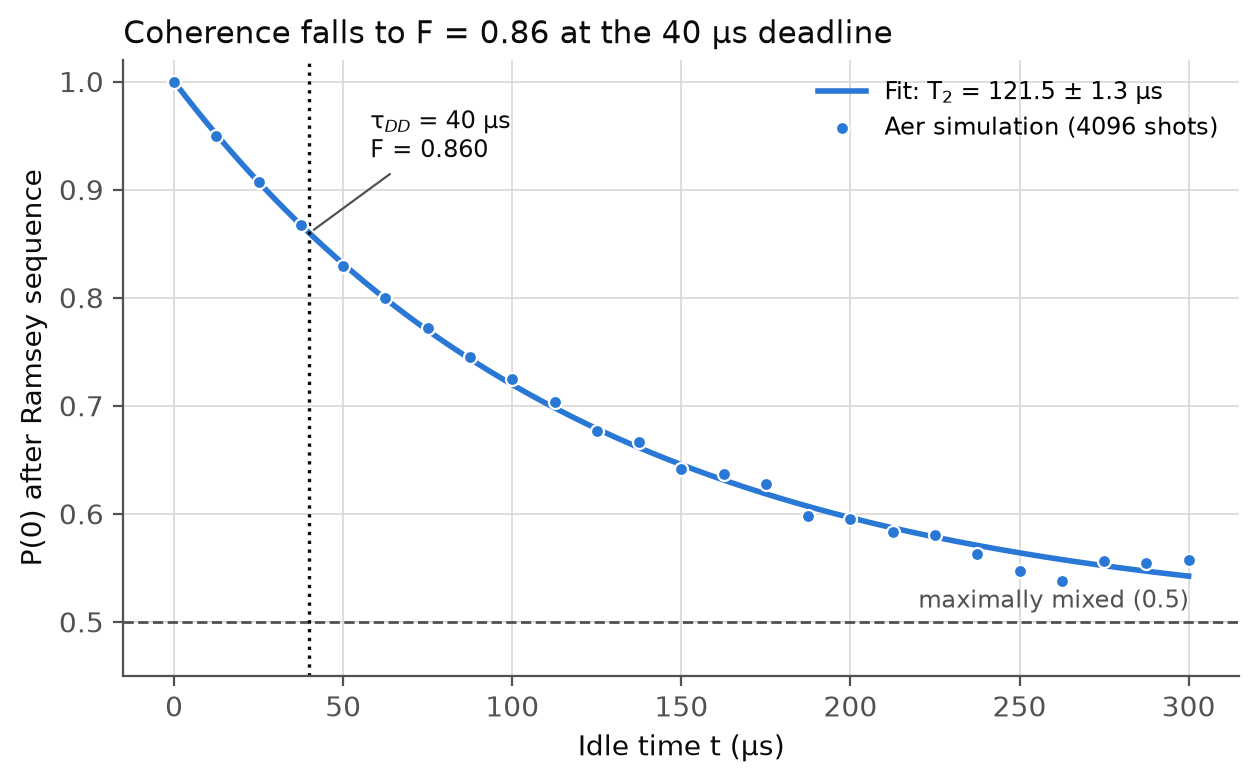

In [8]:
display(Code(inspect.getsource(exp11.ramsey_circuit), language='python'))
run_or_copy(exp11.main, ['w1_coherence.json', 'fig1_coherence_decay.png', 'fig1_coherence_decay.pdf'])
show(OUT / 'fig1_coherence_decay.png', width=700)

**Checks.** The fit should recover the $T_2$ that went into the noise model, and an independent refit of the
saved points (plain `scipy.optimize.curve_fit`, written here rather than imported) should agree with the script.
At the 40 µs deadline Eq. (2) predicts $F = \tfrac12 + \tfrac12 e^{-1/3} = 0.858$.

In [9]:
from scipy.optimize import curve_fit
w1 = load('w1_coherence.json')
t, f = np.array(w1['t_us']), np.array(w1['fidelity'])
popt, pcov = curve_fit(lambda t, T2: 0.5 + 0.5 * np.exp(-t / T2), t, f, p0=[100.0])
T2, T2_se = popt[0], np.sqrt(pcov[0, 0])
print(f"script: T2 = {w1['T2_fit_us']:.2f} ± {w1['T2_fit_err_us']:.2f} µs   independent refit: {T2:.2f} ± {T2_se:.2f} µs")
audit.check('Part 1', 'independent refit agrees with the script', abs(T2 - w1['T2_fit_us']) < 1e-3 * T2)
z = (w1['T2_fit_us'] - 120.0) / w1['T2_fit_err_us']
audit.check('Part 1', 'fitted T2 within 2 standard errors of the 120 µs input', abs(z) < 2, f'z = {z:+.2f}')
audit.check('Part 1', 'reported T2 is 121.5 ± 1.3 µs', f"{w1['T2_fit_us']:.1f} ± {w1['T2_fit_err_us']:.1f}" == '121.5 ± 1.3')
f40 = 0.5 + 0.5 * np.exp(-1 / 3)
audit.check('Part 1', 'fidelity at the 40 µs deadline matches Eq. (2)', abs(w1['fidelity_at_tau_dd'] - f40) < 0.005,
            f"{w1['fidelity_at_tau_dd']:.3f} vs {f40:.3f}")
def reduced_chi2(w):
    t, f = np.array(w['t_us']), np.array(w['fidelity'])
    (T2,), _ = curve_fit(lambda t, T2: 0.5 + 0.5 * np.exp(-t / T2), t, f, p0=[100.0])
    sigma = np.sqrt(np.clip(f * (1 - f), 1e-12, None) / w['params']['shots'])
    resid = f - (0.5 + 0.5 * np.exp(-t / T2))
    return np.sum((resid[1:] / sigma[1:])**2) / (len(t) - 2)       # point 0 has no variance
chi2_red = reduced_chi2(w1)
audit.check('Part 1', 'residuals are consistent with shot noise (reduced chi^2 < 2)', chi2_red < 2,
            f'reduced chi^2 = {chi2_red:.2f}')
audit.check('Part 1', 'reference: reduced chi^2 = 1.03, as quoted in the paper',
            f"{reduced_chi2(load('w1_coherence.json', REF)):.2f}" == '1.03')

script: T2 = 121.49 ± 1.27 µs   independent refit: 121.49 ± 1.27 µs
PASS  independent refit agrees with the script
PASS  fitted T2 within 2 standard errors of the 120 µs input  (z = +1.18)
PASS  reported T2 is 121.5 ± 1.3 µs
PASS  fidelity at the 40 µs deadline matches Eq. (2)  (0.860 vs 0.858)
PASS  residuals are consistent with shot noise (reduced chi^2 < 2)  (reduced chi^2 = 1.03)
PASS  reference: reduced chi^2 = 1.03, as quoted in the paper


True

**Pitfall I hit: the wrong starting state.** My first version started the Ramsey sequence from $|0\rangle$.
Thermal relaxation pulls a qubit *towards* $|0\rangle$, so nothing ever decays, the fit runs off to an absurd
$T_2$ (44,142 µs at the time) and the code still runs without errors. Here is the same experiment from both
states at four idle times:

In [10]:
nm = exp11.build_noise_model(exp11.T1_US * 1e3, exp11.T2_US * 1e3, exp11.GATE_NS)
sim = AerSimulator(noise_model=nm)
from qiskit import QuantumCircuit
def ramsey_from_zero(depth):
    qc = QuantumCircuit(1, 1)
    for _ in range(depth):
        qc.id(0)
    qc.measure(0, 0)
    return qc
rows = []
for depth in (0, 1000, 3000, 6000):
    plus = sim.run(exp11.ramsey_circuit(depth), shots=2048, seed_simulator=11).result().get_counts().get('0', 0) / 2048
    zero = sim.run(ramsey_from_zero(depth), shots=2048, seed_simulator=11).result().get_counts().get('0', 0) / 2048
    rows.append((f'{depth * exp11.GATE_NS / 1e3:.0f}', f'{plus:.3f}', f'{zero:.3f}'))
md_table(['idle time (µs)', 'P(0) starting from |+⟩', 'P(0) starting from |0⟩'], rows)
audit.check('Part 1', 'demo: |+> decays, |0> does not (why the start state matters)',
            float(rows[-1][1]) < 0.6 and float(rows[-1][2]) > 0.99)

| idle time (µs) | P(0) starting from |+⟩ | P(0) starting from |0⟩ |
|---|---|---|
| 0 | 1.000 | 1.000 |
| 50 | 0.838 | 1.000 |
| 150 | 0.648 | 1.000 |
| 300 | 0.555 | 1.000 |

PASS  demo: |+> decays, |0> does not (why the start state matters)


True

**Which errors can a superposition feel?** $|+\rangle$ is an eigenstate of $X$, so an $X$ error does nothing to
it, while $Y$ and $Z$ flip it to $|-\rangle$. Measured in the $X$ basis, its survival under a Pauli error of
probability $p$ should therefore be exactly 1 for $X$ and $1-p$ for $Y$ and $Z$. This is also why a bit-flip code
cannot protect against dephasing on its own.

Pauli X: P(|+> survives) at p = 0.5 → 1.000   max |sim − theory| = 0.0000
Pauli Y: P(|+> survives) at p = 0.5 → 0.494   max |sim − theory| = 0.0085
Pauli Z: P(|+> survives) at p = 0.5 → 0.508   max |sim − theory| = 0.0123


Saved: fig2_pauli_sensitivity.pdf / fig2_pauli_sensitivity.png
Saved: w1_pauli.json
[0.5 s]


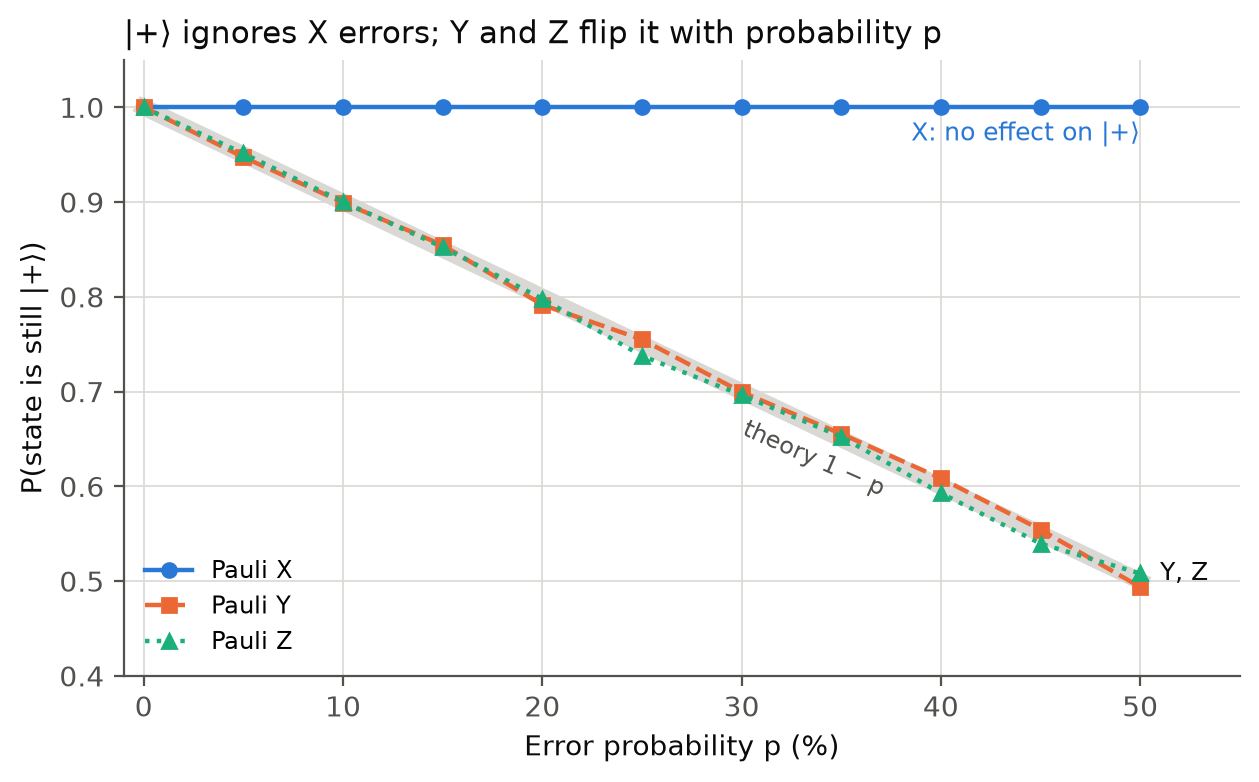

PASS  |+> is immune to X at every p
PASS  Y survival follows 1 - p (all points within 4 sigma)  (max |z| = 1.89)
PASS  Z survival follows 1 - p (all points within 4 sigma)  (max |z| = 2.58)


In [11]:
run_or_copy(exp12.main, ['w1_pauli.json', 'fig2_pauli_sensitivity.png', 'fig2_pauli_sensitivity.pdf'])
show(OUT / 'fig2_pauli_sensitivity.png', width=700)
w1p = load('w1_pauli.json')
p = np.array(w1p['p']); n = w1p['shots']
audit.check('Part 1', '|+> is immune to X at every p', np.all(np.array(w1p['survival']['X']) == 1.0))
for op in 'YZ':
    s = np.array(w1p['survival'][op])
    z = (s - (1 - p)) / np.sqrt(np.clip(p * (1 - p), 1e-12, None) / n)
    audit.check('Part 1', f'{op} survival follows 1 - p (all points within 4 sigma)', np.all(np.abs(z[1:]) < 4),
                f'max |z| = {np.max(np.abs(z[1:])):.2f}')

<a id="part2"></a>
## 3. Part 2: The code and its decoder

**Question.** Does the decoder pick the right correction under realistic noise, and does the code actually
lower the error rate?

**Design.** First, 10,000 complete cycles: each one injects no error or one random bit flip, simulates the
encoded circuit with thermal relaxation (one shot), and times the decode step on its own, syndrome string in,
correction out. Second, the logical error rate at eleven physical error rates from 1% to 50%, 100,000 shots each,
with the correction applied in real time inside the circuit. The decoder is just this:

In [12]:
display(Code(inspect.getsource(bfc.BitFlipCode.decode_syndrome), language='python'))
display(Code(inspect.getsource(bfc.BitFlipCode.run_cycle), language='python'))
run_or_copy(lambda: bfc.run_latency_experiment(n_cycles=10_000, output_file='w2_latencies.json'),
            ['w2_latencies.json'])

def decode_syndrome(self, syndrome_str: str) -> Optional[int]:
        """The whole decoder: one dictionary lookup. Returns the qubit to flip or None."""
        return self.SYNDROME_TABLE[syndrome_str]

def run_cycle(self, logical_state: str = '1',
                  inject_qubit: Optional[int] = None
                  ) -> Tuple[str, Optional[int], float, bool]:
        """
        One QEC cycle: simulate a single shot, then decode with the clock running.
        Returns (syndrome, correction, decode time in ns, decoded == injected).
        """
        counts = self._sim.run(self._circuit(logical_state, inject_qubit), shots=1,
                               seed_simulator=int(self._rng.integers(1, 2**31 - 1))
                               ).result().get_counts()
        syndrome_str = next(iter(counts))

        t0 = time.perf_counter_ns()
        correction = self.decode_syndrome(syndrome_str)
        t1 = time.perf_counter_ns()

        return syndrome_str, correction, float(t1 - t0), correction == inject_qubit

Running 10,000 QEC cycles...


   2,000/10,000   success 98.45%   median decode 1276 ns


   4,000/10,000   success 98.65%   median decode 1245 ns


   6,000/10,000   success 98.70%   median decode 1237 ns


   8,000/10,000   success 98.67%   median decode 1233 ns


  10,000/10,000   success 98.61%   median decode 1240 ns

Saved 10,000 latency samples → w2_latencies.json
Decode latency  median 1240 ns · P99 2693 ns · max 1096047 ns
Syndrome → correction success: 98.61%
Confusion (rows injected none/q0/q1/q2, cols decoded):
  none: [2499, 12, 11, 12]
    q0: [15, 2482, 23, 7]
    q1: [10, 7, 2459, 10]
    q2: [15, 8, 9, 2421]
[15.1 s]


In [13]:
w2 = load('w2_latencies.json')
cm = np.array(w2['confusion_injected_by_decoded'])
md_table(['injected ↓ / decoded →'] + w2['confusion_labels'],
         [[lab] + row.tolist() for lab, row in zip(w2['confusion_labels'], cm)])
audit.check('Part 2', 'confusion matrix accounts for all 10,000 cycles', cm.sum() == w2['n_cycles'] == 10_000)
audit.check('Part 2', 'success rate equals the confusion-matrix diagonal', abs(np.trace(cm) / cm.sum() - w2['success_rate']) < 1e-12)
audit.check('Part 2', 'reported success rate is 98.61%', f"{100 * w2['success_rate']:.2f}" == '98.61')
audit.check('Part 2', 'every decode latency is a positive number', np.all(np.array(w2['latencies_ns']) > 0))

| injected ↓ / decoded → | none | q0 | q1 | q2 |
|---|---|---|---|---|
| none | 2499 | 12 | 11 | 12 |
| q0 | 15 | 2482 | 23 | 7 |
| q1 | 10 | 7 | 2459 | 10 |
| q2 | 15 | 8 | 9 | 2421 |

PASS  confusion matrix accounts for all 10,000 cycles
PASS  success rate equals the confusion-matrix diagonal
PASS  reported success rate is 98.61%
PASS  every decode latency is a positive number


True

The 1.4% of "wrong" decodes are not decoder bugs: thermal relaxation during the 500 ns CNOTs adds its own flips on
top of the injected one, and the table answers what the syndrome says. The diagonal dominates every row.

Now the logical error rate. The noise model applies an $X$ error with probability $p$ to each data qubit, so the
measured rate should follow Eq. (1).

def encoded_circuit() -> QuantumCircuit:
    qd = QuantumRegister(3, 'data')
    qa = QuantumRegister(2, 'anc')
    syn = ClassicalRegister(2, 'syn')
    out = ClassicalRegister(3, 'out')
    qc = QuantumCircuit(qd, qa, syn, out)
    qc.x(qd[0]); qc.cx(qd[0], qd[1]); qc.cx(qd[0], qd[2])     # |111>
    qc.id(qd)                                                 # the noisy moment
    qc.cx(qd[0], qa[1]); qc.cx(qd[1], qa[1])                  # Z0*Z1
    qc.cx(qd[1], qa[0]); qc.cx(qd[2], qa[0])                  # Z1*Z2
    qc.measure(qa, syn)
    # real-time correction: the syndrome decides which X (if any) to apply
    with qc.if_test((syn, 0b10)):
        qc.x(qd[0])
    with qc.if_test((syn, 0b11)):
        qc.x(qd[1])
    with qc.if_test((syn, 0b01)):
        qc.x(qd[2])
    qc.measure(qd, out)
    return qc

p =  0.01   P_L = 0.00039  [0.00029, 0.00053]   theory 0.00030   bare 0.0099   gain ×25.3


p =  0.02   P_L = 0.00119  [0.00099, 0.00142]   theory 0.00118   bare 0.0199   gain ×16.7


p =  0.03   P_L = 0.00245  [0.00216, 0.00278]   theory 0.00265   bare 0.0296   gain ×12.1


p =  0.05   P_L = 0.00718  [0.00668, 0.00772]   theory 0.00725   bare 0.0500   gain ×7.0


p =  0.07   P_L = 0.01447  [0.01375, 0.01523]   theory 0.01401   bare 0.0700   gain ×4.8


... (2 outputs left out)

p =  0.20   P_L = 0.10497  [0.10309, 0.10688]   theory 0.10400   bare 0.1998   gain ×1.9
p =  0.30   P_L = 0.21650  [0.21396, 0.21906]   theory 0.21600   bare 0.3027   gain ×1.4


p =  0.40   P_L = 0.34982  [0.34687, 0.35278]   theory 0.35200   bare 0.3984   gain ×1.1


p =  0.50   P_L = 0.50183  [0.49873, 0.50493]   theory 0.50000   bare 0.4968   gain ×1.0


Saved: fig2b_logical_error.pdf / fig2b_logical_error.png
Saved: w2_logical_error.json
[68.3 s]


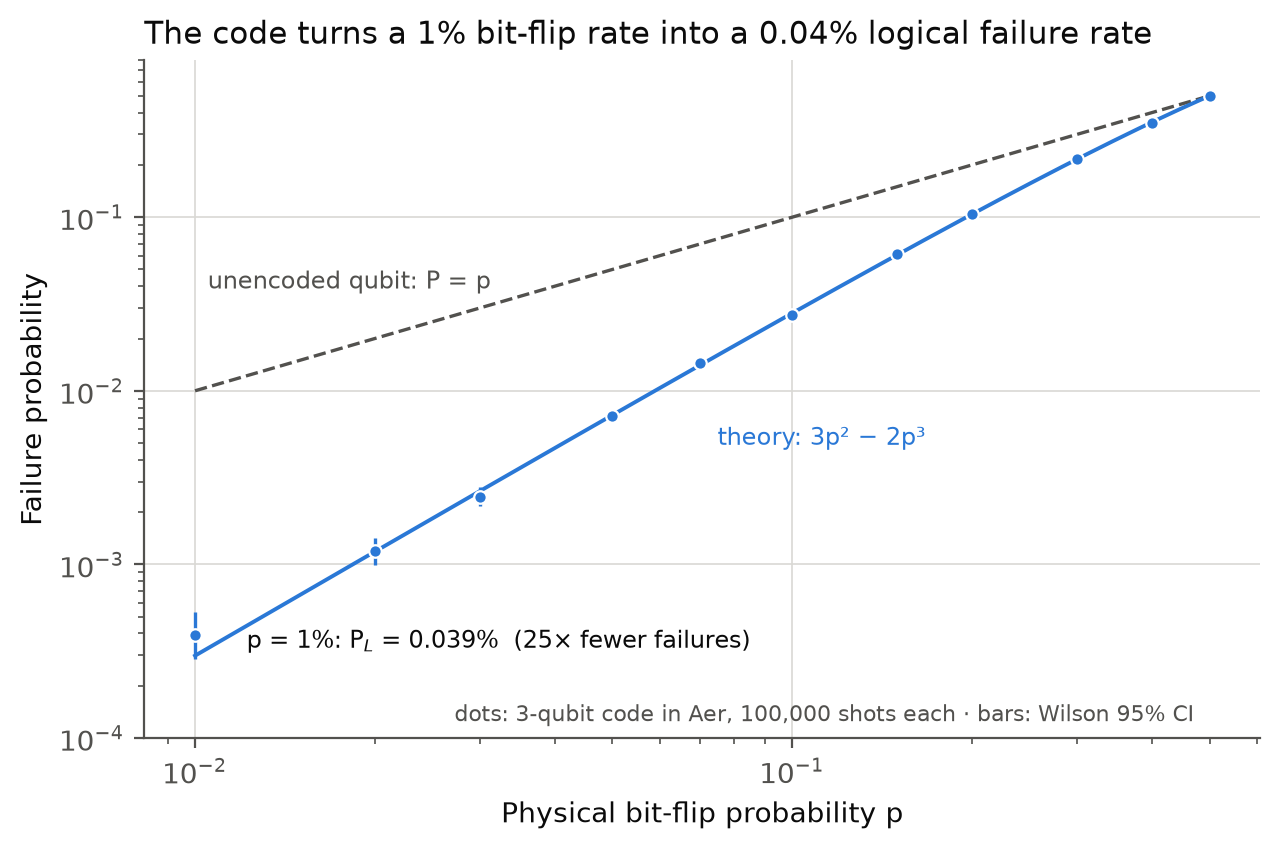

In [14]:
display(Code(inspect.getsource(exp22.encoded_circuit), language='python'))
run_or_copy(exp22.main, ['w2_logical_error.json', 'fig2b_logical_error.png', 'fig2b_logical_error.pdf'])
show(OUT / 'fig2b_logical_error.png', width=700)

In [15]:
w22 = load('w2_logical_error.json')
n = w22['shots']
rows, zs = [], []
for r in w22['rows']:
    sd = np.sqrt(r['theory'] * (1 - r['theory']) / n)
    zs.append((r['logical_fail'] - r['theory']) / sd)
    rows.append((r['p'], f"{r['logical_fail']:.5f}", f"[{r['ci'][0]:.5f}, {r['ci'][1]:.5f}]", f"{r['theory']:.5f}",
                 f'{zs[-1]:+.2f}', f"{r['bare_fail']:.4f}"))
md_table(['p', 'measured P_L', 'Wilson 95% CI', '3p² − 2p³', 'z', 'bare qubit'], rows)
audit.check('Part 2', 'logical error matches 3p^2 - 2p^3 at all 11 points (|z| < 4)', np.all(np.abs(zs) < 4),
            f'max |z| = {np.max(np.abs(zs)):.2f}')
def goodness_of_fit(w):
    z = [(r['logical_fail'] - r['theory']) / np.sqrt(r['theory'] * (1 - r['theory']) / w['shots']) for r in w['rows']]
    chi2 = float(np.sum(np.square(z)))
    return chi2, len(z), stats.chi2.sf(chi2, len(z))
chi2, dof, p_gof = goodness_of_fit(w22)
audit.check('Part 2', 'overall goodness of fit to Eq. (1) (chi^2 test, p > 0.01)', p_gof > 0.01,
            f'chi^2 = {chi2:.1f} on {dof} dof, p = {p_gof:.2f}')
c_ref, d_ref, p_ref = goodness_of_fit(load('w2_logical_error.json', REF))
audit.check('Part 2', 'reference: chi^2 = 12.6 on 11 dof, p = 0.32, as quoted in the paper',
            (f'{c_ref:.1f}', d_ref, f'{p_ref:.2f}') == ('12.6', 11, '0.32'))
below = [r for r in w22['rows'] if r['p'] < 0.5]
audit.check('Part 2', 'code beats a bare qubit for every p < 1/2', all(r['logical_fail'] < r['bare_fail'] for r in below))
r1 = w22['rows'][0]
audit.check('Part 2', 'at p = 1%: P_L = 0.039%, 25x fewer failures than a bare qubit',
            f"{100 * r1['logical_fail']:.3f}" == '0.039' and round(r1['bare_fail'] / r1['logical_fail']) == 25,
            f"{r1['bare_fail'] / r1['logical_fail']:.1f}x")

| p | measured P_L | Wilson 95% CI | 3p² − 2p³ | z | bare qubit |
|---|---|---|---|---|---|
| 0.01 | 0.00039 | [0.00029, 0.00053] | 0.00030 | +1.69 | 0.0099 |
| 0.02 | 0.00119 | [0.00099, 0.00142] | 0.00118 | +0.06 | 0.0199 |
| 0.03 | 0.00245 | [0.00216, 0.00278] | 0.00265 | -1.21 | 0.0296 |
| 0.05 | 0.00718 | [0.00668, 0.00772] | 0.00725 | -0.26 | 0.0500 |
| 0.07 | 0.01447 | [0.01375, 0.01523] | 0.01401 | +1.23 | 0.0700 |
| 0.1 | 0.02726 | [0.02627, 0.02829] | 0.02800 | -1.42 | 0.0989 |
| 0.15 | 0.06098 | [0.05951, 0.06248] | 0.06075 | +0.30 | 0.1481 |
| 0.2 | 0.10497 | [0.10309, 0.10688] | 0.10400 | +1.00 | 0.1998 |
| 0.3 | 0.21650 | [0.21396, 0.21906] | 0.21600 | +0.38 | 0.3027 |
| 0.4 | 0.34982 | [0.34687, 0.35278] | 0.35200 | -1.44 | 0.3984 |
| 0.5 | 0.50183 | [0.49873, 0.50493] | 0.50000 | +1.16 | 0.4968 |

PASS  logical error matches 3p^2 - 2p^3 at all 11 points (|z| < 4)  (max |z| = 1.69)
PASS  overall goodness of fit to Eq. (1) (chi^2 test, p > 0.01)  (chi^2 = 12.6 on 11 dof, p = 0.32)
PASS  reference: chi^2 = 12.6 on 11 dof, p = 0.32, as quoted in the paper
PASS  code beats a bare qubit for every p < 1/2
PASS  at p = 1%: P_L = 0.039%, 25x fewer failures than a bare qubit  (25.3x)


True

At $p = 1\%$ theory predicts $3p^2 - 2p^3 = 0.0298\%$, a 33-fold reduction; the simulation saw 39 failures where
29.8 were expected, a 1.7-standard-deviation fluctuation, so the measured reduction is 25-fold. Both numbers are
reported as they are.

**Pitfall I hit: overlapping random seeds.** When Aer simulates shot by shot (it does for these circuits, using
its stabilizer method), it seeds shot $k$ with `seed + k`. My first version used seeds 7, 8, 9, … one per value of
$p$, so each "independent" point replayed its neighbour's random stream shifted by one shot. The demonstration
below uses the real circuit from Part 2: the run with seed 8 is the run with seed 7, one shot later.
`numpy.random.SeedSequence`, which the experiments now use, spreads the seeds far apart.

In [16]:
enc = exp22.encoded_circuit()
def memory(seed, shots=400):
    res = AerSimulator(noise_model=exp22.noise(0.3), seed_simulator=seed).run(enc, shots=shots, memory=True).result()
    return res.get_memory(), res.results[0].metadata.get('method')
a, method = memory(7)
b, _ = memory(8)
shifted = b[:-1] == a[1:]
print(f'simulation method: {method}')
print(f'seed 8 == seed 7 shifted by one shot: {shifted}  ({len(a) - 1} of {len(a)} shots shared)')
print('SeedSequence seeds used in Part 2:', exp22.SEEDS[:4], '...')
c, _ = memory(exp22.SEEDS[1])
audit.check('Part 2', 'demo: neighbouring Aer seeds share a shifted random stream', shifted)
audit.check('Part 2', 'demo: SeedSequence seeds do not', c[:-1] != a[1:] and c != a)

simulation method: stabilizer
seed 8 == seed 7 shifted by one shot: True  (399 of 400 shots shared)
SeedSequence seeds used in Part 2: [2083679832, 3939563265, 4185785210, 142198000] ...
PASS  demo: neighbouring Aer seeds share a shifted random stream
PASS  demo: SeedSequence seeds do not


True

<a id="part3"></a>
## 4. Part 3: Decoder latency

**Question.** How long does decoding take, and how often is it late?

Part 2 timed the Python decoder inside a busy simulation loop. Here the same table lookup is timed in isolation,
three ways:

* **Python**: a dictionary lookup between two `time.perf_counter_ns()` calls;
* **C**: the same table in C, timed *inside* C with `clock_gettime(CLOCK_MONOTONIC)`, so no Python overhead
  is counted;
* **bare metal (modelled, not measured)**: a Cortex-M7 at 480 MHz with a 41-cycle worst case (85.4 ns) and 5%
  jitter. It is there for scale only and never enters a statistical test.

Each tier runs 10,000 timed cycles after 1,000 warm-up cycles. Both measured tiers also time the **clock alone**
(two reads with nothing in between): at these speeds the stopwatch is a large part of what you see.

In [17]:
display(Code(filename=str(SRC / 'qec_decode.c'), language='c'))
display(Code(inspect.getsource(exp3.python_tier), language='python'))
display(Code(inspect.getsource(exp3.vr_exact), language='python'))

/* qec_decode.c
 * The same look-up-table decoder as the Python version, written in C so I can
 * see how much of the latency is Python itself. Timing happens inside C.
 * Author: Swayam Shakya
 *
 * Build (Linux / macOS / WSL):
 *     gcc -O2 -shared -fPIC -o qec_decode.so qec_decode.c
 * (run_all.sh does this for you and puts the library in build/)
 */
#define _POSIX_C_SOURCE 200809L   /* without this, -std=c11 hides clock_gettime */
#include <stdint.h>
#include <time.h>

/* Syndrome packed into an int (bit 1 = Z0Z1, bit 0 = Z1Z2) -> qubit to flip.
 * -1 means "no correction".
 *   0b00 = 0 -> nothing        0b01 = 1 -> qubit 2
 *   0b10 = 2 -> qubit 0        0b11 = 3 -> qubit 1                       */
static const int8_t LUT[4] = { -1, 2, 0, 1 };

int8_t decode_syndrome(uint8_t syndrome) {
    return LUT[syndrome & 0x3];
}

/* Monotonic clock in ns. Never jumps backwards, unlike wall-clock time. */
static inline int64_t now_ns(void) {
    struct timespec ts;
    clock_gettime(CLOCK_MONOTONIC, &ts);
    return (int64_t)ts.tv_sec * 1000000000LL + (int64_t)ts.tv_nsec;
}

/* Decode n syndromes and time each one separately; latencies go into out[]. */
void decode_batch(const uint8_t *syndromes, int64_t *out, int n) {
    for (int i = 0; i < n; i++) {
        int64_t t0 = now_ns();
        volatile int8_t correction = decode_syndrome(syndromes[i]);
        int64_t t1 = now_ns();
        (void)correction;          /* volatile, so -O2 can't throw the lookup away */
        out[i] = t1 - t0;
    }
}

/* Timer floor: two clock reads back to back with nothing in between.
 * This is what "measuring" costs by itself; subtract its median from the
 * decode median to get the real work. */
void timer_floor_batch(int64_t *out, int n) {
    for (int i = 0; i < n; i++) {
        int64_t t0 = now_ns();
        int64_t t1 = now_ns();
        out[i] = t1 - t0;
    }
}

def python_tier(n: int) -> np.ndarray:
    syndromes = RNG.choice(list(SYNDROME_TABLE), n + WARMUP).tolist()
    lat = np.empty(n + WARMUP)
    for i, s in enumerate(syndromes):
        t0 = time.perf_counter_ns()
        _ = SYNDROME_TABLE[s]
        lat[i] = time.perf_counter_ns() - t0
    return lat[WARMUP:]

def vr_exact(lat: np.ndarray, tau: float):
    """VR(τ) in % with its exact (Clopper–Pearson) 95 % interval."""
    k, n = int(np.sum(lat > tau)), lat.size
    lo, hi = proportion_confint(k, n, alpha=0.05, method='beta')
    return 100 * k / n, 100 * lo, 100 * hi, k

**Step 1: what shape is the latency distribution?** `fit_distribution.py` fits log-normal, gamma and Weibull
distributions to the Part 2 latencies and estimates the tail index. It is run exactly as the command line would
run it.

In [18]:
import runpy, contextlib
def run_script(name, *args):
    argv = sys.argv
    sys.argv = [name, *args]
    try:
        runpy.run_path(str(SRC / name), run_name='__main__')
    finally:
        sys.argv = argv
run_or_copy(lambda: run_script('fit_distribution.py'), ['w3_fit.json'])
fit = load('w3_fit.json')
ref_fit = load('w3_fit.json', REF)
audit.check('Part 3', 'log-normal is rejected by Anderson-Darling (p <= 0.01)', fit['ad_p'] <= 0.01, f"A² = {fit['ad_stat']:.1f}")
audit.check('Part 3', 'reference run: log-normal is the closest family yet still rejected',
            ref_fit['best_ks'] == 'lognorm' and not ref_fit['ad_lognormal_pass'])

--- Distribution fitting ---
n = 10,000   median = 1240 ns
Anderson–Darling on log(L): A² = 274.41   p ≤ 0.01   log-normal accepted at 5%: False
KS lognorm      D = 0.1119   p = 1.91e-109
KS gamma        D = 0.2454   p = 0.00e+00
KS weibull_min  D = 0.2715   p = 0.00e+00
Closest family by KS distance: lognorm
Hill tail index (top 5%): α = 2.46  → moderate tail
Saved: w3_fit.json
[0.1 s]
PASS  log-normal is rejected by Anderson-Darling (p <= 0.01)  (A² = 274.4)
PASS  reference run: log-normal is the closest family yet still rejected


True

No standard family fits: the bulk is roughly log-normal, but a handful of cycles are far slower than the median
(in the reference data the slowest is 146 times the median). Those are the events that matter for a deadline.

**Step 2: the three tiers.** This is a fresh timing run on *this* machine, so the numbers will differ from the
reference run (and from run to run). That variation is part of the finding.

Tier                      median      P99     P99.9        max   floor  misses@40µs
Python                       105      174       329      44823      61       1 / 10000
C extension                   26       27        28     582955      25       1 / 10000
Bare-metal (modelled)         85       95        99        102     nan       0 / 10000


Saved: fig3_main_result.pdf / fig3_main_result.png
Saved: w3_latencies.json
[4.0 s]


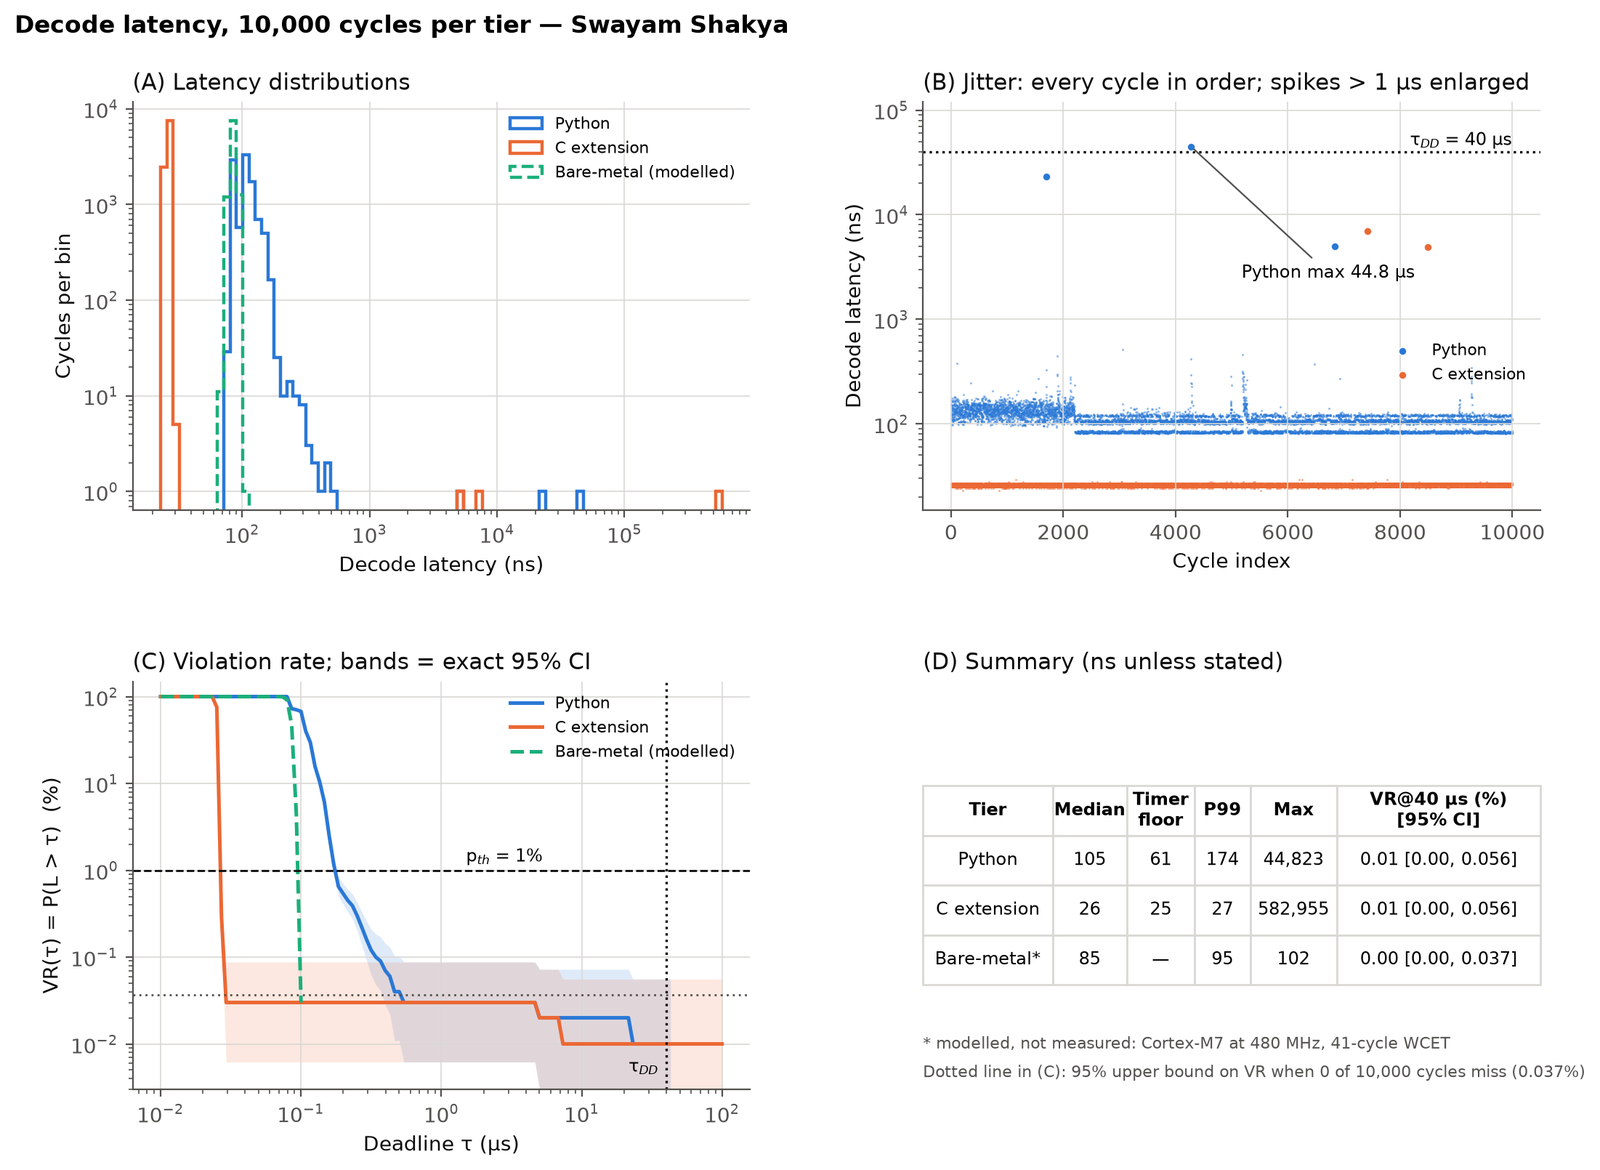

In [19]:
def timing():
    exp3.RNG = np.random.default_rng(seed=0)      # same start as a fresh `python experiment_3_jitter_profiler.py`
    exp3.main()
run_or_copy(timing, ['w3_latencies.json', 'fig3_main_result.png', 'fig3_main_result.pdf'])
show(OUT / 'fig3_main_result.png', width=950)

**Step 3: is the tail stable?** One run's worst stall turned out to be close to a random number, so the two
measured tiers are repeated ten more times (another 100,000 cycles each).

In [20]:
def repeats():
    exp3.RNG = np.random.default_rng(seed=0)      # same start as `--repeats 10` in a fresh process
    exp3.repeat_study(10)
run_or_copy(repeats, ['w3_repeats.json'])
rep = load('w3_repeats.json')
md_table(['run', 'Python median (ns)', 'Python max (µs)', 'Python misses', 'C median (ns)', 'C max (µs)', 'C misses'],
         [(i + 1, f"{a['median_ns']:.0f}", f"{a['max_ns'] / 1e3:.1f}", a['misses_at_tau_dd'],
           f"{b['median_ns']:.0f}", f"{b['max_ns'] / 1e3:.1f}", b['misses_at_tau_dd'])
          for i, (a, b) in enumerate(zip(rep['runs']['Python'], rep['runs']['C extension']))])

run 1/10: Python: median 104 ns, max 23.1 µs, misses 0   C extension: median 32 ns, max 18.5 µs, misses 0
run 2/10: Python: median 103 ns, max 17.5 µs, misses 0   C extension: median 26 ns, max 41.6 µs, misses 1
run 3/10: Python: median 105 ns, max 37.7 µs, misses 0   C extension: median 26 ns, max 0.2 µs, misses 0
run 4/10: Python: median 103 ns, max 31.6 µs, misses 0   C extension: median 26 ns, max 0.1 µs, misses 0
run 5/10: Python: median 103 ns, max 19.5 µs, misses 0   C extension: median 27 ns, max 0.1 µs, misses 0
run 6/10: Python: median 103 ns, max 24.3 µs, misses 0   C extension: median 26 ns, max 0.1 µs, misses 0
run 7/10: Python: median 103 ns, max 17.2 µs, misses 0   C extension: median 26 ns, max 0.2 µs, misses 0
run 8/10: Python: median 105 ns, max 34.4 µs, misses 0   C extension: median 26 ns, max 29.6 µs, misses 0
run 9/10: Python: median 106 ns, max 28.0 µs, misses 0   C extension: median 30 ns, max 46.2 µs, misses 1
run 10/10: Python: median 104 ns, max 22.6 µs, miss

| run | Python median (ns) | Python max (µs) | Python misses | C median (ns) | C max (µs) | C misses |
|---|---|---|---|---|---|---|
| 1 | 104 | 23.1 | 0 | 32 | 18.5 | 0 |
| 2 | 103 | 17.5 | 0 | 26 | 41.6 | 1 |
| 3 | 105 | 37.7 | 0 | 26 | 0.2 | 0 |
| 4 | 103 | 31.6 | 0 | 26 | 0.1 | 0 |
| 5 | 103 | 19.5 | 0 | 27 | 0.1 | 0 |
| 6 | 103 | 24.3 | 0 | 26 | 0.1 | 0 |
| 7 | 103 | 17.2 | 0 | 26 | 0.2 | 0 |
| 8 | 105 | 34.4 | 0 | 26 | 29.6 | 0 |
| 9 | 106 | 28.0 | 0 | 30 | 46.2 | 1 |
| 10 | 104 | 22.6 | 0 | 26 | 32.7 | 0 |

**Step 4: the statistics.** `analysis_paper_ready.py` computes $\tau^*$ with its bootstrap interval, the Hill
index, Anderson–Darling, stall counts and the Mann–Whitney comparison, and writes `paper_stats.json`, the LaTeX
table and the tail figure.

Tier                     median   P99=τ*      95% CI of τ*  headroom  Hill α   VR@40µs


Python                      105      174        [171, 178]      230×    6.87     0.01%


C extension                  26       27          [27, 27]     1481×   22.88     0.01%


Bare-metal (modelled)        85       95          [95, 96]      420×   52.66     0.00%

Stalls (L > 1 µs): Python: 3 of 10,000, median 23.0 µs   C extension: 3 of 10,000, median 7.0 µs   Bare-metal (modelled): 0 of 10,000

Mann–Whitney U (Python vs C): U = 99970005, p = 0.00e+00, r_rb = +0.999, median ratio = 4.0×
Repeats, Python: 0 misses in 100,000 cycles → VR@40 µs ≤ 0.0037% (95% upper bound)
Repeats, C extension: 2 misses in 100,000 cycles → VR@40 µs ≤ 0.0072% (95% upper bound)


Saved: fig4_tail_diagnostics.pdf / fig4_tail_diagnostics.png
Saved: table1.tex
Saved: paper_stats.json
[5.0 s]


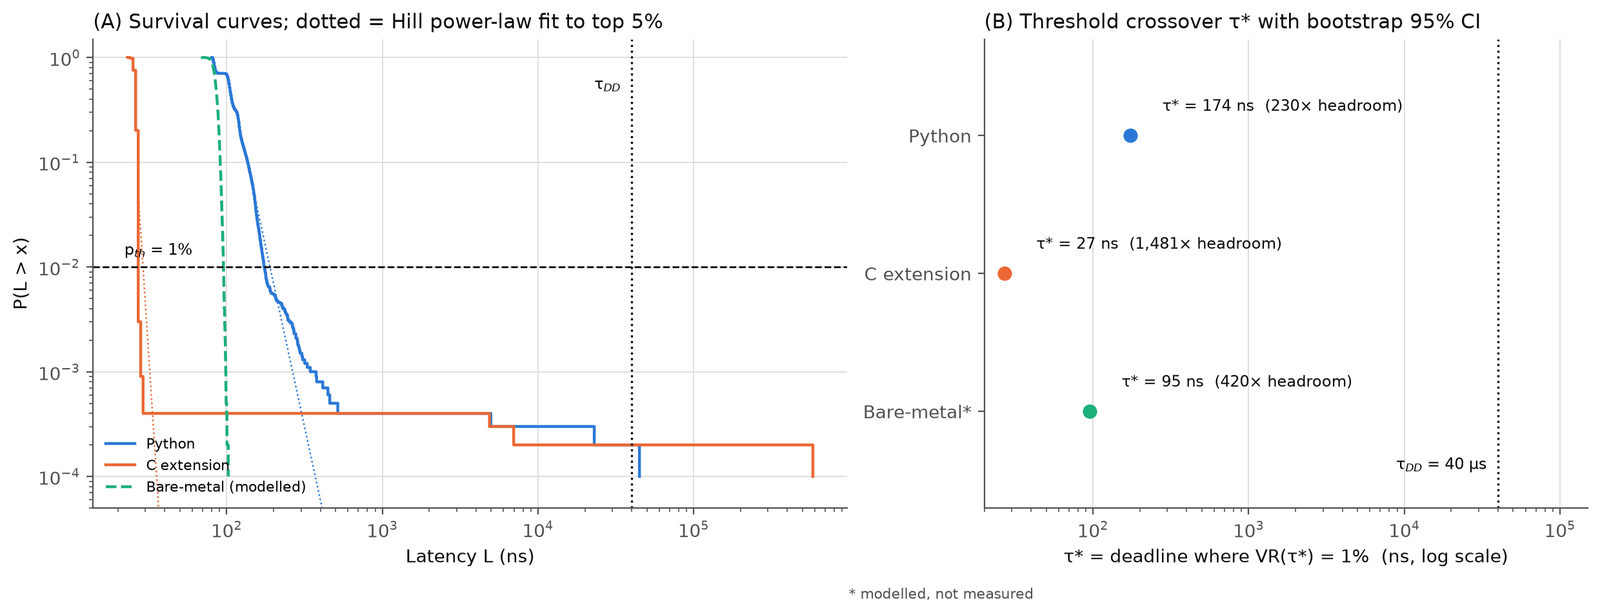

In [21]:
run_or_copy(analysis.main, ['paper_stats.json', 'table1.tex', 'fig4_tail_diagnostics.png', 'fig4_tail_diagnostics.pdf'])
show(OUT / 'fig4_tail_diagnostics.png', width=950)

**Independent re-check of the statistics.** Everything below is recomputed from the raw per-cycle latencies with
code written in this cell (beta quantiles for Clopper–Pearson, ranks for Mann–Whitney, Eq. (6) for Hill) and
compared with what the scripts stored. It runs on this notebook's fresh run and on the committed reference run.

In [22]:
def cp(k, n, a=0.05):
    lo = 0.0 if k == 0 else stats.beta.ppf(a / 2, k, n - k + 1)
    hi = 1.0 if k == n else stats.beta.ppf(1 - a / 2, k + 1, n - k)
    return lo, hi

def hill(x, frac=0.05):
    s = np.sort(x[x > 0])[::-1]
    k = max(2, int(len(s) * frac))
    return k / np.sum(np.log(s[:k] / s[k]))

def mann_whitney_by_ranks(a, b):
    ranks = stats.rankdata(np.concatenate([a, b]))
    u1 = ranks[:a.size].sum() - a.size * (a.size + 1) / 2
    return u1, 2 * u1 / (a.size * b.size) - 1

def recheck(folder, label):
    raw, ps = load('w3_latencies.json', folder), load('paper_stats.json', folder)
    ok = True
    for tier, lat in raw['latencies_ns'].items():
        lat = np.asarray(lat, float); s = ps['tiers'][tier]
        k = int(np.sum(lat > 40_000)); lo, hi = cp(k, lat.size)
        ok &= np.isclose(s['median_ns'], np.median(lat)) and np.isclose(s['tau_star_ns'], np.percentile(lat, 99))
        ok &= s['misses_at_tau_dd'] == k and np.allclose(s['vr_at_tau_dd_ci_pct'], [100 * lo, 100 * hi], atol=1e-10)
        ok &= np.isclose(s['hill_alpha'], hill(lat), rtol=1e-12)
        ok &= s['stalls_over_1us'] == int(np.sum(lat > 1_000))
        ok &= s['tau_star_ci_ns'][0] <= s['tau_star_ns'] <= s['tau_star_ci_ns'][1]
    a, b = (np.asarray(raw['latencies_ns'][t], float) for t in ('Python', 'C extension'))
    u1, r = mann_whitney_by_ranks(a, b)
    ok &= np.isclose(u1, ps['mann_whitney']['U']) and np.isclose(r, ps['mann_whitney']['rank_biserial_r'])
    audit.check('Part 3', f'{label}: medians, tau*, CP intervals, Hill, stalls and Mann-Whitney recomputed', ok)
    for tier in ('Python', 'C extension'):
        s = raw['summary'][tier]
        audit.check('Part 3', f'{label}: {tier} timer floor is below its median latency',
                    s['timer_floor_median_ns'] < s['median_ns'],
                    f"floor {s['timer_floor_median_ns']:.0f} ns, median {s['median_ns']:.0f} ns")
    audit.check('Part 3', f'{label}: C is faster than Python (r_rb > 0.9)', r > 0.9, f'r_rb = {r:+.3f}')
    bm = np.asarray(raw['latencies_ns']['Bare-metal (modelled)'])
    audit.check('Part 3', f'{label}: bare-metal model centred on its 85.4 ns WCET', abs(np.median(bm) / (41 / 480e6 * 1e9) - 1) < 0.01)
    return ps

ps_new = recheck(OUT, 'this run')
ps_ref = recheck(REF, 'reference run')

PASS  this run: medians, tau*, CP intervals, Hill, stalls and Mann-Whitney recomputed
PASS  this run: Python timer floor is below its median latency  (floor 61 ns, median 105 ns)
PASS  this run: C extension timer floor is below its median latency  (floor 25 ns, median 26 ns)
PASS  this run: C is faster than Python (r_rb > 0.9)  (r_rb = +0.999)
PASS  this run: bare-metal model centred on its 85.4 ns WCET
PASS  reference run: medians, tau*, CP intervals, Hill, stalls and Mann-Whitney recomputed
PASS  reference run: Python timer floor is below its median latency  (floor 63 ns, median 113 ns)
PASS  reference run: C extension timer floor is below its median latency  (floor 26 ns, median 31 ns)
PASS  reference run: C is faster than Python (r_rb > 0.9)  (r_rb = +0.998)
PASS  reference run: bare-metal model centred on its 85.4 ns WCET


**This run next to the reference run.** The reference figures in the paper come from the run committed in
`reference_results/` (14 October 2026). The headline claims are checked against it here.

| run | tier | median (ns) | τ* (ns) [95% CI] | max (µs) | cycles > 1 µs | misses at 40 µs |
|---|---|---|---|---|---|---|
| reference | Python | 113 | 268 [248, 290] | 41.8 | 7 | 1 |
| reference | C extension | 31 | 46 [45, 47] | 23.0 | 1 | 0 |
| this run | Python | 105 | 174 [171, 178] | 44.8 | 3 | 1 |
| this run | C extension | 26 | 27 [27, 27] | 583.0 | 3 | 1 |

PASS  reference: medians 113 ns (Python) and 31 ns (C)
PASS  reference: tau* = 268 ns and 46 ns
PASS  reference: C is 3.6x faster at the median
PASS  reference: real decode work about 50 ns (Python) and 5 ns (C) above the clock
PASS  reference: clock alone costs 63 ns (Python) and 26 ns (C)


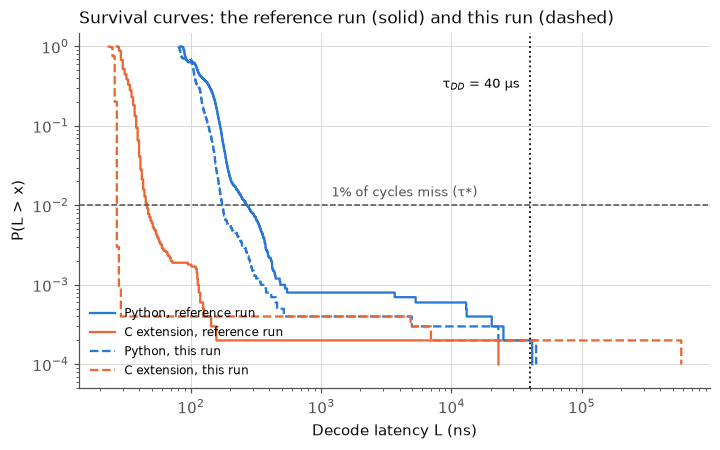

In [23]:
rows = []
for label, ps in (('reference', ps_ref), ('this run', ps_new)):
    for tier in ('Python', 'C extension'):
        s = ps['tiers'][tier]
        rows.append((label, tier, f"{s['median_ns']:.0f}", f"{s['tau_star_ns']:.0f} [{s['tau_star_ci_ns'][0]:.0f}, {s['tau_star_ci_ns'][1]:.0f}]",
                     f"{s['max_ns'] / 1e3:.1f}", s['stalls_over_1us'], s['misses_at_tau_dd']))
md_table(['run', 'tier', 'median (ns)', 'τ* (ns) [95% CI]', 'max (µs)', 'cycles > 1 µs', 'misses at 40 µs'], rows)

P, C = ps_ref['tiers']['Python'], ps_ref['tiers']['C extension']
w3ref = load('w3_latencies.json', REF)['summary']
audit.check('Part 3', 'reference: medians 113 ns (Python) and 31 ns (C)', (P['median_ns'], C['median_ns']) == (113.0, 31.0))
audit.check('Part 3', 'reference: tau* = 268 ns and 46 ns', (round(P['tau_star_ns']), round(C['tau_star_ns'])) == (268, 46))
audit.check('Part 3', 'reference: C is 3.6x faster at the median', f"{ps_ref['mann_whitney']['median_ratio']:.1f}" == '3.6')
audit.check('Part 3', 'reference: real decode work about 50 ns (Python) and 5 ns (C) above the clock',
            (w3ref['Python']['net_decode_median_ns'], w3ref['C extension']['net_decode_median_ns']) == (50.0, 5.0))
audit.check('Part 3', 'reference: clock alone costs 63 ns (Python) and 26 ns (C)',
            (w3ref['Python']['timer_floor_median_ns'], w3ref['C extension']['timer_floor_median_ns']) == (63.0, 26.0))

fig, ax = plt.subplots(figsize=(7.4, 4.2))
for folder, ls, lab in ((REF, '-', 'reference run'), (OUT, '--', 'this run')):
    raw = load('w3_latencies.json', folder)['latencies_ns']
    for tier, col in (('Python', qec_style.BLUE), ('C extension', qec_style.ORANGE)):
        s = np.sort(np.asarray(raw[tier], float))
        ax.step(s, 1 - np.arange(s.size) / s.size, where='post', color=col, ls=ls, lw=1.5, label=f'{tier}, {lab}')
ax.axvline(40_000, color=qec_style.INK, ls=':', lw=1.2); ax.text(40_000 * 0.85, 0.3, 'τ$_{DD}$ = 40 µs', ha='right', fontsize=8.5)
ax.axhline(0.01, color=qec_style.MUTED, ls='--', lw=1); ax.text(1.2e3, 0.013, '1% of cycles miss (τ*)', fontsize=8.5, color=qec_style.MUTED)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_ylim(5e-5, 1.5)
ax.set_xlabel('Decode latency L (ns)'); ax.set_ylabel('P(L > x)')
ax.set_title('Survival curves: the reference run (solid) and this run (dashed)', loc='left')
ax.legend(fontsize=8, loc='lower left'); plt.show()

**Pitfall I hit: bootstrap intervals for rare events.** With zero misses every bootstrap resample also has zero
misses, so the interval collapses to $[0, 0]$, claiming a certainty the data cannot give. Clopper–Pearson still
gives an upper bound of about $3.689/n$:

In [24]:
lat = np.full(10_000, 100.0)                         # 10,000 cycles, none late
print('bootstrap interval with 0 misses:', exp3.vr_bootstrap(lat, 40_000), '(no interval at all)')
vr, lo, hi, k = exp3.vr_exact(lat, 40_000)
print(f'Clopper-Pearson with 0 misses: [{lo:.4f}%, {hi:.4f}%]   3.689/n = {100 * 3.689 / 1e4:.4f}%')
audit.check('Part 3', 'demo: bootstrap collapses at zero misses, Clopper-Pearson does not',
            exp3.vr_bootstrap(lat, 40_000) is None and abs(hi - 100 * (1 - 0.025 ** (1 / 1e4))) < 1e-9)
lat[123] = 50_000.0                                  # now one late cycle
vr, lo, hi, k = exp3.vr_exact(lat, 40_000)
print(f'one miss: VR = {vr:.3f}%, Clopper-Pearson [{lo:.4f}%, {hi:.4f}%], bootstrap {exp3.vr_bootstrap(lat, 40_000)}')

bootstrap interval with 0 misses: None (no interval at all)
Clopper-Pearson with 0 misses: [0.0000%, 0.0369%]   3.689/n = 0.0369%
PASS  demo: bootstrap collapses at zero misses, Clopper-Pearson does not


one miss: VR = 0.010%, Clopper-Pearson [0.0003%, 0.0557%], bootstrap [0.0, 0.03]


### 4.1 Six complete runs, pooled

A single run cannot pin down events this rare, so the timing experiment (main run plus ten repeats, 110,000
cycles per tier) was run six times on 2-vCPU cloud machines between 14 October and 11 November 2026. Their
summaries are committed in `reproducibility_runs/`. This notebook's own run is shown separately and not added to
the pool, so the published numbers do not depend on when the notebook was last executed.

In [25]:
RR = ROOT / 'reproducibility_runs'
runs = sorted(d.name for d in RR.iterdir() if d.is_dir())
rows, pool = [], {'Python': [0, 0], 'C extension': [0, 0]}
for i, r in enumerate(runs):
    ps = load('paper_stats.json', RR / r); rp = load('w3_repeats.json', RR / r); envr = load('environment.json', RR / r)
    cells = [f'R{i}', envr['date'], envr['cpu'].replace('Intel Xeon ', ''), envr['python']]
    for tier in ('Python', 'C extension'):
        allr = [ps['tiers'][tier]] + rp['runs'][tier]
        misses = sum(x['misses_at_tau_dd'] for x in allr)
        cycles = ps['tiers'][tier]['n'] + rp['n_per_run'] * len(rp['runs'][tier])
        pool[tier][0] += misses; pool[tier][1] += cycles
        cells += [f"{ps['tiers'][tier]['tau_star_ns']:.0f}", f"{max(x['max_ns'] for x in allr) / 1e3:,.1f}", misses]
    rows.append(cells)
md_table(['run', 'date', 'CPU', 'Python', 'Py τ* (ns)', 'Py worst (µs)', 'Py misses', 'C τ* (ns)', 'C worst (µs)', 'C misses'], rows)

(kp, npy), (kc, nc) = pool['Python'], pool['C extension']
fisher = stats.fisher_exact([[kp, npy - kp], [kc, nc - kc]])
md_table(['tier', 'misses', 'cycles', 'VR', '95% upper bound'],
         [(t, k, f'{n:,}', f'{100 * k / n:.5f}%', f'{100 * cp(k, n)[1]:.5f}%') for t, (k, n) in pool.items()])
print(f'Fisher exact test, Python vs C miss rates: p = {fisher.pvalue:.2e}')

PN = json.loads((ROOT / 'paper' / 'paper_numbers.json').read_text())['pooled']
audit.check('Part 3', 'pooled counts: Python 14 and C 1 misses in 660,000 cycles each',
            (kp, kc, npy, nc) == (14, 1, 660_000, 660_000))
audit.check('Part 3', 'pooled upper bounds 0.0036% and 0.00084% (as stated)',
            f'{100 * cp(kp, npy)[1]:.4f}' == '0.0036' and f'{100 * cp(kc, nc)[1]:.5f}' == '0.00084')
audit.check('Part 3', 'paper_numbers.json agrees with the recomputed pool',
            (PN['Python']['misses'], PN['C extension']['misses']) == (kp, kc)
            and np.isclose(PN['Python']['cp_upper_pct'], 100 * cp(kp, npy)[1]) and np.isclose(PN['C extension']['cp_upper_pct'], 100 * cp(kc, nc)[1]))
audit.check('Part 3', 'C misses significantly less often than Python (Fisher p < 0.001)', fisher.pvalue < 0.001, f'p = {fisher.pvalue:.1e}')
worst_py_us = max(float(r[5].replace(',', '')) for r in rows)
worst_c_us = max(float(r[8]) for r in rows)
audit.check('Part 3', 'slowest cycles across runs: 1.39 ms (Python) and 67.4 µs (C)', f'{worst_py_us / 1e3:.2f}' == '1.39' and f'{worst_c_us:.1f}' == '67.4')

| run | date | CPU | Python | Py τ* (ns) | Py worst (µs) | Py misses | C τ* (ns) | C worst (µs) | C misses |
|---|---|---|---|---|---|---|---|---|---|
| R0 | 2026-10-14 | 2.1 GHz, 2 vCPUs | 3.12.3 | 268 | 41.8 | 1 | 46 | 26.5 | 0 |
| R1 | 2026-10-14 | 2.1 GHz, 2 vCPUs | 3.13.16 | 216 | 74.3 | 5 | 40 | 67.4 | 1 |
| R2 | 2026-10-14 | 2.1 GHz, 2 vCPUs | 3.13.16 | 189 | 1,388.3 | 2 | 29 | 30.5 | 0 |
| R3 | 2026-10-26 | 2.8 GHz, 2 vCPUs | 3.13.16 | 399 | 67.2 | 3 | 110 | 26.0 | 0 |
| R4 | 2026-11-11 | 2.1 GHz, 2 vCPUs | 3.13.16 | 105 | 170.9 | 2 | 27 | 29.5 | 0 |
| R5 | 2026-11-11 | 2.1 GHz, 2 vCPUs | 3.13.16 | 197 | 42.9 | 1 | 40 | 37.6 | 0 |

| tier | misses | cycles | VR | 95% upper bound |
|---|---|---|---|---|
| Python | 14 | 660,000 | 0.00212% | 0.00356% |
| C extension | 1 | 660,000 | 0.00015% | 0.00084% |

Fisher exact test, Python vs C miss rates: p = 9.77e-04
PASS  pooled counts: Python 14 and C 1 misses in 660,000 cycles each
PASS  pooled upper bounds 0.0036% and 0.00084% (as stated)
PASS  paper_numbers.json agrees with the recomputed pool
PASS  C misses significantly less often than Python (Fisher p < 0.001)  (p = 9.8e-04)
PASS  slowest cycles across runs: 1.39 ms (Python) and 67.4 µs (C)


True

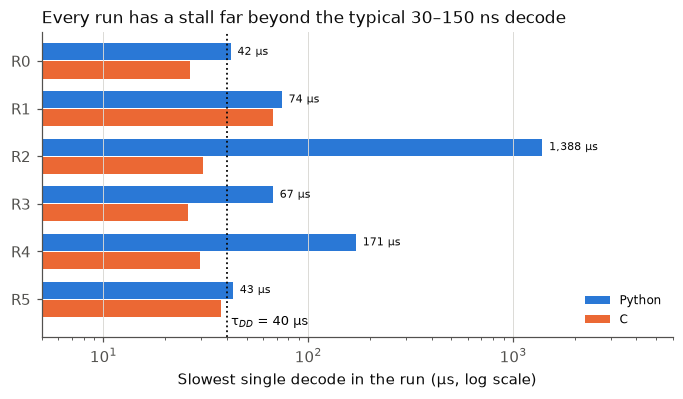

In [26]:
fig, ax = plt.subplots(figsize=(7.4, 3.6))
y = np.arange(len(rows))[::-1]
py_worst = [float(r[5].replace(',', '')) for r in rows]; c_worst = [float(r[8]) for r in rows]
ax.barh(y + 0.19, py_worst, height=0.36, color=qec_style.BLUE, label='Python')
ax.barh(y - 0.19, c_worst, height=0.36, color=qec_style.ORANGE, label='C')
for yi, v in zip(y, py_worst):
    ax.text(v * 1.08, yi + 0.19, f'{v:,.0f} µs', va='center', fontsize=7.5, color=qec_style.INK)
ax.axvline(40, color=qec_style.INK, ls=':', lw=1.2); ax.text(42, y[-1] - 0.55, 'τ$_{DD}$ = 40 µs', fontsize=8.5)
ax.set_xscale('log'); ax.set_xlim(5, 6000); ax.set_ylim(y[-1] - 0.8, y[0] + 0.6)
ax.set_yticks(y, [r[0] for r in rows]); ax.grid(axis='y', visible=False)
ax.set_xlabel('Slowest single decode in the run (µs, log scale)')
ax.set_title('Every run has a stall far beyond the typical 30–150 ns decode', loc='left')
ax.legend(fontsize=8, loc='lower right'); plt.show()

**What this says.** A table lookup costs about 50 ns of real work in Python and 5 ns in C; the rest of the
typical latency is the clock itself. Deadline misses happen when the decoder loses the CPU for a while, most
likely to the operating system (scheduling, interrupts, hypervisor steal time; this is inferred by elimination,
not traced), and those stalls range from tens of microseconds to over a millisecond. C is faster and misses less
often, but it stalls too. That points at the host rather than the language, which is why real-time systems use
kernels such as PREEMPT_RT [[27](#ref-27)] and why production decoders run on dedicated hardware
[[28](#ref-28), [29](#ref-29)].

<a id="part4"></a>
## 5. Part 4: Calibrated IBM device replicas

**Question.** Under realistic device noise, what does the code buy, and what does every microsecond of decoder
delay cost?

**Design.** `FakeKingston` (156-qubit Heron r2) and `FakeSherbrooke` (127-qubit Eagle r3) are noise models built
from snapshots of real IBM devices' calibration data [[30](#ref-30)]; they run locally through the client-side
`Sampler` of qiskit-ibm-runtime 0.50 [[31](#ref-31), [32](#ref-32)]. Three circuits, 4,000 shots each, all holding logical
$|1\rangle$:

* **bare**: one physical qubit that idles exactly as long as the encoded circuit's encode-and-syndrome stage;
* **offline**: the code with the syndrome measured and decoded afterwards in software, shot by shot;
* **real-time**: the code with the correction applied inside the circuit by `if_test` feed-forward.

All three are pinned to the same physical qubits. Then a sweep inserts an explicit wait of 0–80 µs between the
syndrome measurement and the correction: Aer only adds noise to instructions, so a `delay` is the only way the
replica can feel a slow decoder.

def encoded(feedforward: bool, wait_dt: int = 0) -> QuantumCircuit:
    """The encoded circuit. wait_dt > 0 parks the data qubits for that long
    between reading the syndrome and fixing the error - my stand-in for a slow
    classical decoder. (Aer only adds noise to instructions, so an explicit
    delay is the only way the replica can "see" latency.)"""
    qd = QuantumRegister(3, 'data')
    qa = QuantumRegister(2, 'anc')
    syn = ClassicalRegister(2, 'syn')
    out = ClassicalRegister(3, 'out')
    qc = QuantumCircuit(qd, qa, syn, out,
                        name='realtime' if feedforward else 'offline')
    qc.x(qd[0]); qc.cx(qd[0], qd[1]); qc.cx(qd[0], qd[2])      # |111>
    qc.cx(qd[0], qa[1]); qc.cx(qd[1], qa[1])                   # ancilla 1 ← Z0·Z1
    qc.cx(qd[1], qa[0]); qc.cx(qd[2], qa[0])                   # ancilla 0 ← Z1·Z2
    qc.measure(qa, syn)
    if wait_dt > 0:
        qc.delay(wait_dt, qd, unit='dt')
    if feedforward:
        with qc.if_test((syn, 0b10)):
            qc.x(qd[0])
        with qc.if_test((syn, 0b11)):
            qc.x(qd[1])
        with qc.if_test((syn, 0b01)):
            qc.x(qd[2])
    qc.barrier(qd)
    qc.measure(qd, out)
    return qc

Device fake_kingston: median T1 = 283 µs, median T2 = 144 µs → τ_DD = T2/3 = 48 µs
Encode + syndrome stage = 3.15 µs (bare-qubit delay)
  bare      depth   3   2-qubit gates  0   qubits [109]
  offline   depth  22   2-qubit gates 12   qubits [108, 109, 110, 118, 129]
  realtime  depth  26   2-qubit gates 12   qubits [108, 109, 110, 118, 129]



── Results on fake_kingston (4000 shots per circuit) ──
bare                     F =  97.88%   95% CI [97.38, 98.28]
majority vote only       F =  99.72%   95% CI [99.51, 99.85]
offline decode           F =  99.70%   95% CI [99.48, 99.83]
real-time feed-forward   F =  99.55%   95% CI [99.29, 99.72]
bare vs real-time        Δ = +1.68 pp   χ² = 42.84   p = 5.93e-11
bare vs offline decode   Δ = +1.82 pp   χ² = 54.10   p = 1.91e-13
offline vs real-time     Δ = -0.15 pp   χ² = 0.84   p = 0.36
Saved: w4_results_fake_kingston.json


Saved: fig5_hardware_fake_kingston.pdf / fig5_hardware_fake_kingston.png
[17.3 s]


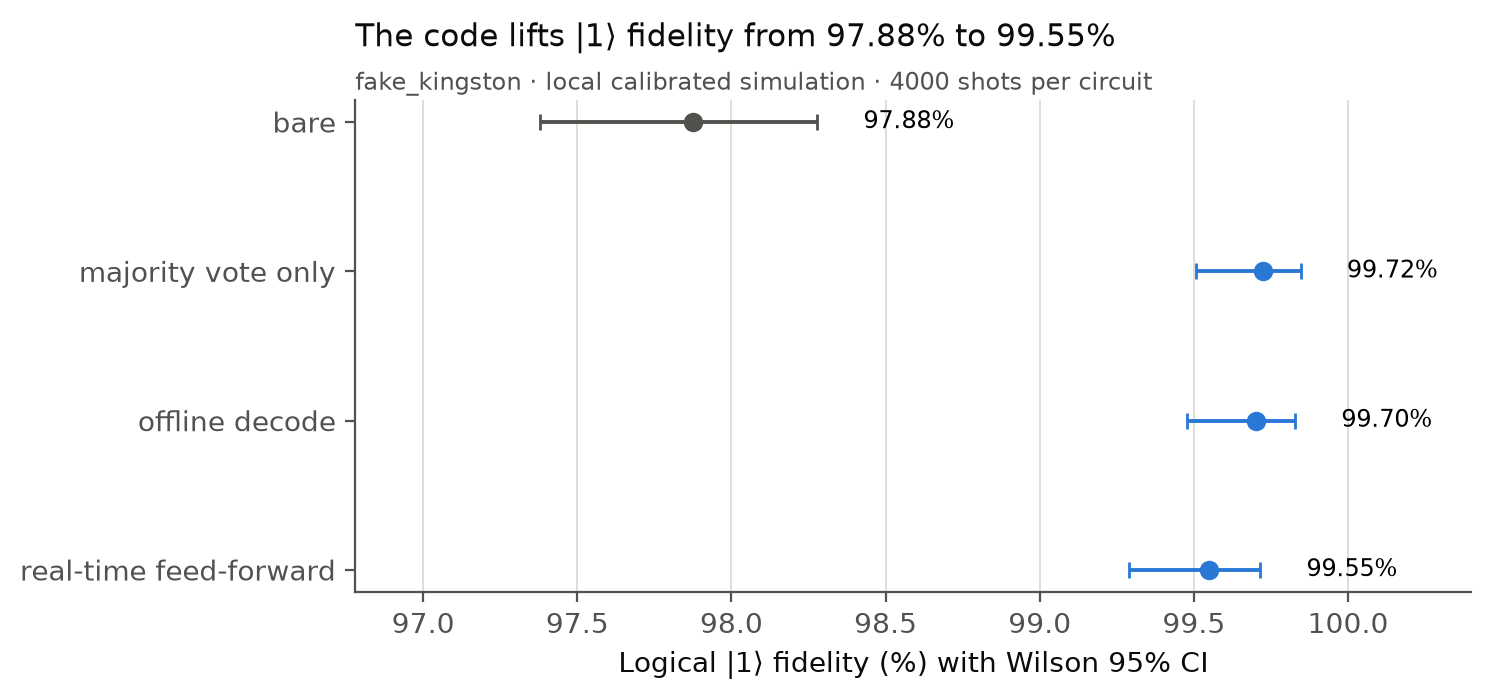

Device fake_sherbrooke: median T1 = 278 µs, median T2 = 170 µs → τ_DD = T2/3 = 57 µs
Encode + syndrome stage = 6.76 µs (bare-qubit delay)
  bare      depth   3   2-qubit gates  0   qubits [60]
  offline   depth  43   2-qubit gates 12   qubits [41, 53, 59, 60, 61]
  realtime  depth  46   2-qubit gates 12   qubits [41, 53, 59, 60, 61]



── Results on fake_sherbrooke (4000 shots per circuit) ──
bare                     F =  97.38%   95% CI [96.83, 97.83]
majority vote only       F =  99.28%   95% CI [98.96, 99.49]
offline decode           F =  99.10%   95% CI [98.76, 99.35]
real-time feed-forward   F =  99.00%   95% CI [98.64, 99.26]
bare vs real-time        Δ = +1.62 pp   χ² = 28.77   p = 8.15e-08
bare vs offline decode   Δ = +1.73 pp   χ² = 33.38   p = 7.57e-09
offline vs real-time     Δ = -0.10 pp   χ² = 0.12   p = 0.73
Saved: w4_results_fake_sherbrooke.json


Saved: fig5_hardware_fake_sherbrooke.pdf / fig5_hardware_fake_sherbrooke.png
[6.9 s]


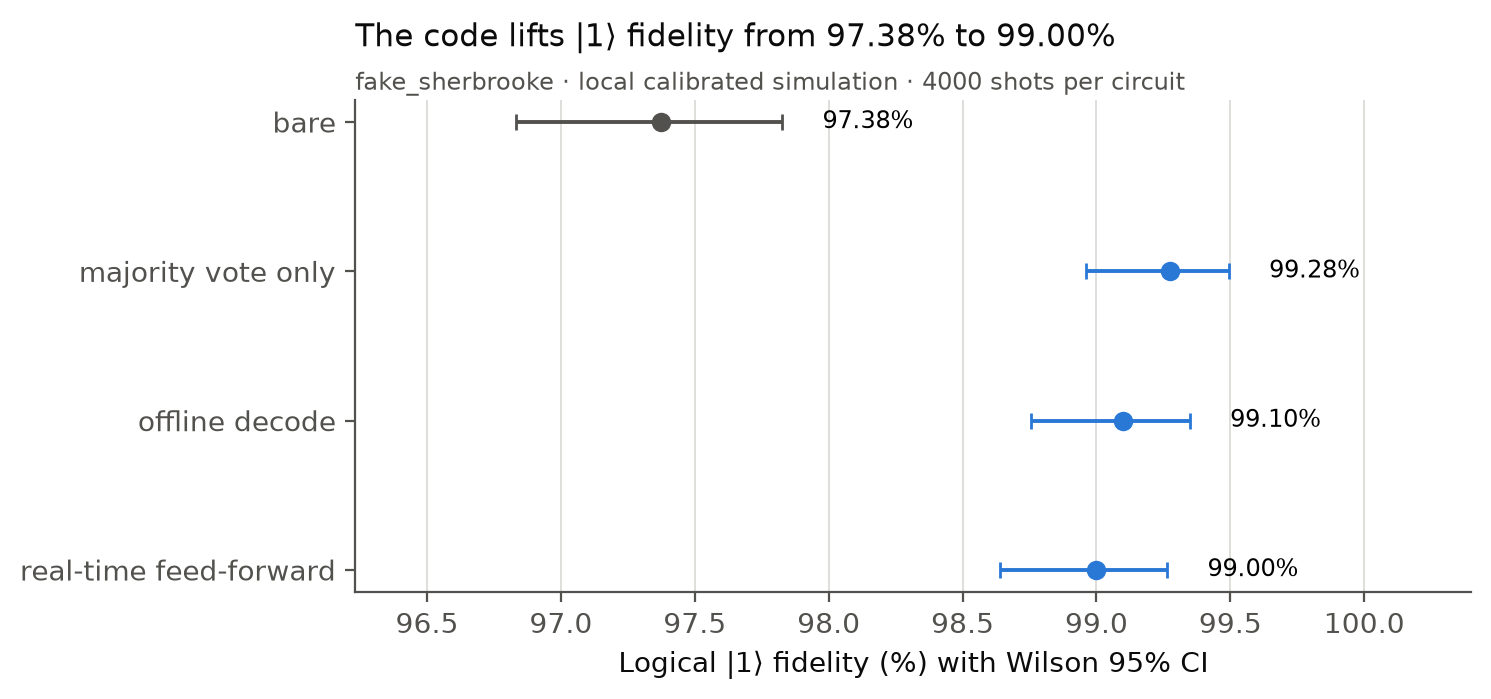

In [27]:
display(Code(inspect.getsource(exp4.encoded), language='python'))
for dev in ('FakeKingston', 'FakeSherbrooke'):
    stem = 'fake_' + dev[4:].lower()
    run_or_copy(lambda: exp4.run_local(dev), [f'w4_results_{stem}.json', f'fig5_hardware_{stem}.png', f'fig5_hardware_{stem}.pdf'])
    show(OUT / f'fig5_hardware_{stem}.png', width=650)

In [28]:
claims = {'fake_kingston': ('Heron r2', '+1.68'), 'fake_sherbrooke': ('Eagle r3', '+1.62')}
rows = []
for stem, (chip, gain) in claims.items():
    w4 = load(f'w4_results_{stem}.json')
    lg, ts, tr = w4['logical'], w4['tests'], w4['transpiled']
    for name, v in lg.items():
        rows.append((chip, name, f"{100 * v['fidelity']:.2f}", f"[{100 * v['ci'][0]:.2f}, {100 * v['ci'][1]:.2f}]"))
    d = ts['bare vs real-time']
    audit.check('Part 4', f'{chip}: real-time correction beats the bare qubit by {gain} points (p < 0.001)',
                f"{d['difference_pct_points']:+.2f}" == gain and d['p'] < 0.001, f"chi^2 = {d['chi2']:.1f}")
    o = ts['offline vs real-time']
    audit.check('Part 4', f'{chip}: offline and real-time decoding are statistically indistinguishable', o['p'] > 0.05,
                f"diff {o['difference_pct_points']:+.2f} pp, p = {o['p']:.2f}")
    audit.check('Part 4', f'{chip}: offline and real-time circuits share one physical layout',
                tr['offline']['physical_qubits'] == tr['realtime']['physical_qubits']
                and tr['bare']['physical_qubits'][0] in tr['offline']['physical_qubits'], tr['offline']['physical_qubits'])
    # independent recount of one chi-square test
    k_b, k_r, n = lg['bare']['correct'], lg['real-time feed-forward']['correct'], w4['shots']
    chi = stats.chi2_contingency([[k_b, n - k_b], [k_r, n - k_r]])
    audit.check('Part 4', f'{chip}: chi-square test recomputed', np.isclose(chi.statistic, d['chi2']) and np.isclose(chi.pvalue, d['p']))
md_table(['device', 'protocol', 'fidelity (%)', 'Wilson 95% CI'], rows)

PASS  Heron r2: real-time correction beats the bare qubit by +1.68 points (p < 0.001)  (chi^2 = 42.8)
PASS  Heron r2: offline and real-time decoding are statistically indistinguishable  (diff -0.15 pp, p = 0.36)
PASS  Heron r2: offline and real-time circuits share one physical layout  ([108, 109, 110, 118, 129])
PASS  Heron r2: chi-square test recomputed
PASS  Eagle r3: real-time correction beats the bare qubit by +1.62 points (p < 0.001)  (chi^2 = 28.8)
PASS  Eagle r3: offline and real-time decoding are statistically indistinguishable  (diff -0.10 pp, p = 0.73)
PASS  Eagle r3: offline and real-time circuits share one physical layout  ([41, 53, 59, 60, 61])
PASS  Eagle r3: chi-square test recomputed


| device | protocol | fidelity (%) | Wilson 95% CI |
|---|---|---|---|
| Heron r2 | bare | 97.88 | [97.38, 98.28] |
| Heron r2 | majority vote only | 99.72 | [99.51, 99.85] |
| Heron r2 | offline decode | 99.70 | [99.48, 99.83] |
| Heron r2 | real-time feed-forward | 99.55 | [99.29, 99.72] |
| Eagle r3 | bare | 97.38 | [96.83, 97.83] |
| Eagle r3 | majority vote only | 99.28 | [98.96, 99.49] |
| Eagle r3 | offline decode | 99.10 | [98.76, 99.35] |
| Eagle r3 | real-time feed-forward | 99.00 | [98.64, 99.26] |

The code with real-time feed-forward beats a bare qubit by about 1.6–1.7 points on both devices. Offline and
real-time decoding agree within noise: on these replicas the feed-forward itself costs nothing, because Aer does
not model the controller's own delay. The sweep adds that delay explicitly:

wait   0.00 µs   encoded error   0.45%   bare error   2.12%
wait   0.50 µs   encoded error   0.38%   bare error   2.28%
wait   1.00 µs   encoded error   0.38%   bare error   2.45%
wait   2.00 µs   encoded error   0.42%   bare error   2.85%
wait   5.00 µs   encoded error   0.62%   bare error   4.27%
wait  10.00 µs   encoded error   1.25%   bare error   5.93%
wait  20.00 µs   encoded error   2.12%   bare error   9.23%
wait  40.00 µs   encoded error   5.63%   bare error  15.62%
wait  80.00 µs   encoded error  16.27%   bare error  25.75%
Encoded logical error doubles at a decoder wait of ≈ 7.6 µs
Saved: w4_sweep_fake_kingston.json


Saved: fig6_latency_sweep_fake_kingston.pdf / fig6_latency_sweep_fake_kingston.png
[117.2 s]


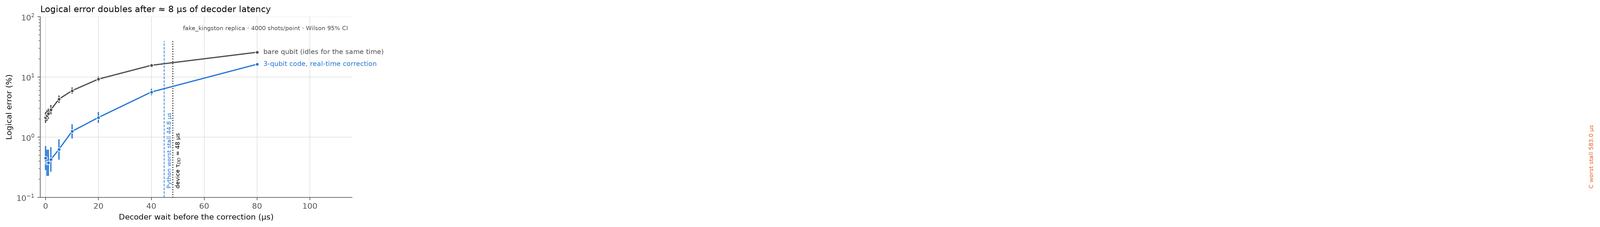

wait   0.00 µs   encoded error   1.00%   bare error   2.62%
wait   0.50 µs   encoded error   1.00%   bare error   2.75%
wait   1.00 µs   encoded error   1.02%   bare error   2.92%
wait   2.00 µs   encoded error   1.00%   bare error   3.12%
wait   5.00 µs   encoded error   1.30%   bare error   4.03%
wait  10.00 µs   encoded error   1.72%   bare error   5.27%
wait  20.00 µs   encoded error   2.90%   bare error   7.33%
wait  40.00 µs   encoded error   5.73%   bare error  11.85%
wait  80.00 µs   encoded error  12.62%   bare error  19.13%
Encoded logical error doubles at a decoder wait of ≈ 12.8 µs
Saved: w4_sweep_fake_sherbrooke.json


Saved: fig6_latency_sweep_fake_sherbrooke.pdf / fig6_latency_sweep_fake_sherbrooke.png
[42.6 s]


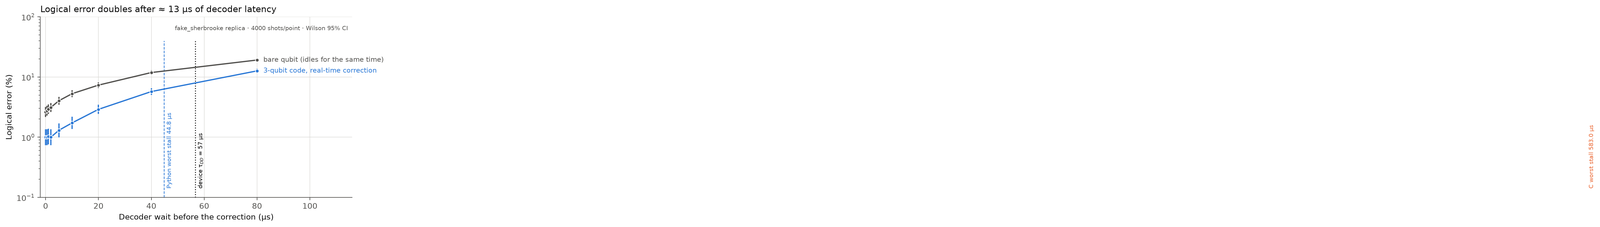

In [29]:
for dev in ('FakeKingston', 'FakeSherbrooke'):
    stem = 'fake_' + dev[4:].lower()
    run_or_copy(lambda: exp4.run_sweep(dev), [f'w4_sweep_{stem}.json', f'fig6_latency_sweep_{stem}.png', f'fig6_latency_sweep_{stem}.pdf'])
    show(OUT / f'fig6_latency_sweep_{stem}.png', width=700)

(The dashed lines mark the worst stalls of whichever timing run sits in the output folder, here this notebook's.)

**Checks.** The doubling point is recomputed independently by log-interpolation, and it should sit far below each
device's own deadline ($T_2/3$ = 48 µs on Heron, 57 µs on Eagle): the deadline is a ceiling, not a target.

In [30]:
claims = {'fake_kingston': ('Heron r2', '7.6'), 'fake_sherbrooke': ('Eagle r3', '12.8')}
for stem, (chip, dbl) in claims.items():
    sw = load(f'w4_sweep_{stem}.json')
    w = np.array([r['wait_us'] for r in sw['rows']]); e = np.array([r['encoded_error'] for r in sw['rows']])
    j = int(np.nonzero(e >= 2 * e[0])[0][0])
    mine = np.exp(np.interp(np.log(2 * e[0]), np.log(e[j - 1:j + 1]), np.log(np.maximum(w[j - 1:j + 1], 1e-9))))
    lin = np.interp(np.log(2 * e[0]), np.log(e[j - 1:j + 1]), w[j - 1:j + 1])
    audit.check('Part 4', f'{chip}: doubling wait recomputed ({lin:.2f} µs)', np.isclose(lin, sw['doubling_wait_us']))
    audit.check('Part 4', f'{chip}: logical error doubles after {dbl} µs of waiting', f"{sw['doubling_wait_us']:.1f}" == dbl)
    audit.check('Part 4', f'{chip}: doubling happens well before the device deadline', sw['doubling_wait_us'] < sw['tau_dd_us'] / 3,
                f"τ_DD = {sw['tau_dd_us']:.0f} µs")
    audit.check('Part 4', f'{chip}: error at 80 µs wait is at least 10x the no-wait error', e[-1] > 10 * e[0], f'{e[-1] / e[0]:.0f}x')
    audit.check('Part 4', f'{chip}: the code still beats a bare qubit at every wait',
                all(r['encoded_error'] < r['bare_error'] for r in sw['rows']))

PASS  Heron r2: doubling wait recomputed (7.63 µs)
PASS  Heron r2: logical error doubles after 7.6 µs of waiting
PASS  Heron r2: doubling happens well before the device deadline  (τ_DD = 48 µs)
PASS  Heron r2: error at 80 µs wait is at least 10x the no-wait error  (36x)
PASS  Heron r2: the code still beats a bare qubit at every wait
PASS  Eagle r3: doubling wait recomputed (12.85 µs)
PASS  Eagle r3: logical error doubles after 12.8 µs of waiting
PASS  Eagle r3: doubling happens well before the device deadline  (τ_DD = 57 µs)
PASS  Eagle r3: error at 80 µs wait is at least 10x the no-wait error  (13x)
PASS  Eagle r3: the code still beats a bare qubit at every wait


**Two transpiler pitfalls I hit.** (1) My first "time-matched" bare qubit was padded with `id` gates, which the
transpiler simply deletes, so it was not time-matched at all; a `delay` instruction survives. (2) Letting the
transpiler place each circuit separately put them on different physical qubits, and a 0.42-point "difference"
between offline and real-time correction turned out to be nothing but better qubits. Both, demonstrated:

In [31]:
from qiskit import transpile
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime.fake_provider import FakeKingston, FakeSherbrooke
kingston = FakeKingston()
pad_id = QuantumCircuit(1, 1); pad_id.x(0)
for _ in range(20):
    pad_id.id(0)
pad_id.measure(0, 0)
pad_delay = QuantumCircuit(1, 1); pad_delay.x(0); pad_delay.delay(1000, 0, unit='dt'); pad_delay.measure(0, 0)
ops_id = dict(transpile(pad_id, kingston, optimization_level=1).count_ops())
ops_delay = dict(transpile(pad_delay, kingston, optimization_level=1).count_ops())
print('20 id gates after transpiling :', ops_id)
print('one delay after transpiling   :', ops_delay)
audit.check('Part 4', 'demo: the transpiler deletes id padding but keeps a delay', 'id' not in ops_id and ops_delay.get('delay') == 1)

sher = FakeSherbrooke()
def phys(c):
    return sorted({c.find_bit(q).index for inst in c.data for q in inst.qubits})
free = {}
for name, ff in (('offline', False), ('real-time', True)):
    pm = generate_preset_pass_manager(optimization_level=2, backend=sher, seed_transpiler=7 if ff else 3)
    free[name] = phys(pm.run(exp4.encoded(ff)))
pm, _, layout = exp4.fixed_layout_pms(sher)
pinned = {'offline': phys(pm.run(exp4.encoded(False))), 'real-time': phys(pm.run(exp4.encoded(True)))}
md_table(['layout', 'offline qubits', 'real-time qubits'],
         [('chosen separately', free['offline'], free['real-time']), ('pinned (as used)', pinned['offline'], pinned['real-time'])])
audit.check('Part 4', 'pinned layout puts both encoded circuits on the same qubits', pinned['offline'] == pinned['real-time'])

20 id gates after transpiling : {'x': 1, 'measure': 1}
one delay after transpiling   : {'x': 1, 'delay': 1, 'measure': 1}
PASS  demo: the transpiler deletes id padding but keeps a delay


| layout | offline qubits | real-time qubits |
|---|---|---|
| chosen separately | [41, 53, 59, 60, 61] | [103, 104, 105, 106, 111] |
| pinned (as used) | [41, 53, 59, 60, 61] | [41, 53, 59, 60, 61] |

PASS  pinned layout puts both encoded circuits on the same qubits


True

<a id="testing"></a>
## 6. Testing

The repository's automated test suite (`tests/`) checks the syndrome table on every input, the C decoder against
the Python table, the statistics on data with known answers (a Pareto tail with $\alpha = 3$, log-normal samples,
zero-miss intervals), the device-replica layout and the command-line error handling. It runs here exactly as it
runs in continuous integration.

In [32]:
t0 = time.perf_counter()
res = subprocess.run([sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', '--color=no', 'tests'],
                     cwd=ROOT, capture_output=True, text=True, env={**os.environ, 'PYTHONDONTWRITEBYTECODE': '1'})
print(res.stdout[-2500:], res.stderr[-1500:])
summary = re.search(r'(\d+) passed', res.stdout)
failed = re.search(r'(\d+) (failed|error)', res.stdout)
audit.check('Testing', 'pytest suite passes', res.returncode == 0 and summary and not failed,
            f'{summary.group(0) if summary else "no summary"} in {time.perf_counter() - t0:.0f} s')

.....................................                                    [100%]
37 passed in 7.21s
 
PASS  pytest suite passes  (37 passed in 9 s)


True

**Extra tests that only make sense here.** Randomised checks across the whole input space, comparing pieces of the
project that were written independently: the C table against the Python table on 100,000 random syndromes; the
offline software decoder of Part 4 against the parity logic of the code on all eight possible flip patterns; and the
statsmodels Clopper–Pearson interval used by the experiments against the beta-quantile formula on a grid of
$(k, n)$.

In [33]:
import ctypes
lib = exp3.load_c_library(str(LIB))
lib.decode_syndrome.argtypes = [ctypes.c_uint8]; lib.decode_syndrome.restype = ctypes.c_int8
rng = np.random.default_rng(2026)
syn = rng.integers(0, 4, 100_000)
table = {int(k, 2): (-1 if v is None else v) for k, v in bfc.BitFlipCode.SYNDROME_TABLE.items()}
audit.check('Testing', 'C and Python tables agree on 100,000 random syndromes',
            all(lib.decode_syndrome(int(s)) == table[int(s)] for s in syn))

ok = True
for pattern in product([0, 1], repeat=3):                         # every possible set of flips on |111>
    data = ''.join(str(1 - b) for b in pattern[::-1])               # Qiskit order: q2 q1 q0
    syn_str = f'{pattern[0] ^ pattern[1]}{pattern[1] ^ pattern[2]}'
    fixed = exp4.decode_offline(syn_str, data)
    expected = sum(pattern) <= 1                                   # the code fixes at most one flip
    ok &= exp4.majority_is_one(fixed) == expected
    ok &= (fixed == '111') == (sum(pattern) <= 1)
audit.check('Testing', 'offline decoder of Part 4 matches the code logic on all 8 flip patterns', ok)

from statsmodels.stats.proportion import proportion_confint
grid_ok = all(np.allclose(proportion_confint(k, n, method='beta'), cp(k, n), atol=1e-12)
              for n in (10, 1_000, 110_000, 660_000) for k in (0, 1, 2, 5, 14) if k <= n)
audit.check('Testing', 'statsmodels Clopper-Pearson equals the beta-quantile formula on a (k, n) grid', grid_ok)

audit.check('Testing', 'Hill estimator recovers a known Pareto tail (alpha = 3)',
            abs(hill((1 / np.random.default_rng(0).random(200_000)) ** (1 / 3)) - 3) < 0.24)

PASS  C and Python tables agree on 100,000 random syndromes
PASS  offline decoder of Part 4 matches the code logic on all 8 flip patterns
PASS  statsmodels Clopper-Pearson equals the beta-quantile formula on a (k, n) grid
PASS  Hill estimator recovers a known Pareto tail (alpha = 3)


True

<a id="audit"></a>
## 7. Reproducibility and consistency audit

**Seeded results.** Parts 1, 2 and 4 use fixed seeds, so on the same kind of CPU they must reproduce the committed
reference results exactly, every number in every file. On a different CPU, Aer's floating point can move the odd
shot (on a 2.8 GHz Xeon the Eagle sweep shifted by one shot in 4,000, and the original code shows the same shift
there), so the check also compares the underlying shot counts and accepts a difference of at most two shots.

In [34]:
def shot_counts(name, folder=None):
    # every seeded result reduced to the integer shot counts it was computed from
    d = load(name, folder)
    if name == 'w1_coherence.json':
        return np.rint(np.array(d['fidelity']) * d['params']['shots'])
    if name == 'w1_pauli.json':
        return np.rint(np.concatenate([d['survival'][k] for k in 'XYZ']) * d['shots'])
    if name == 'w2_logical_error.json':
        return np.rint(np.array([[r['logical_fail'], r['bare_fail']] for r in d['rows']]).ravel() * d['shots'])
    if name.startswith('w4_results'):
        return np.array([v['correct'] for v in d['logical'].values()], float)
    if name.startswith('w4_sweep'):
        return np.rint(np.array([[r['encoded_error'], r['bare_error']] for r in d['rows']]).ravel() * d['shots'])
    raise KeyError(name)

def without_env(d):
    return {k: v for k, v in d.items() if k != 'environment'}

seeded = ['w1_coherence.json', 'w1_pauli.json', 'w2_logical_error.json', 'w4_results_fake_kingston.json',
          'w4_results_fake_sherbrooke.json', 'w4_sweep_fake_kingston.json', 'w4_sweep_fake_sherbrooke.json']
rows = []
for name in seeded:
    identical = without_env(load(name)) == without_env(load(name, REF))
    a, b = shot_counts(name), shot_counts(name, REF)
    shift = int(np.max(np.abs(a - b))) if a.shape == b.shape else None
    verdict = ('identical' if identical else
               f'differs by at most {shift} shot(s) (CPU floating point)' if shift is not None and shift <= 2 else 'differs')
    rows.append((name, verdict))
    audit.check('Reproducibility', f'{name} reproduces the reference', identical or (shift is not None and shift <= 2), verdict)
w2n, w2r = load('w2_latencies.json'), load('w2_latencies.json', REF)
same_decodes = w2n['success_rate'] == w2r['success_rate'] and w2n['confusion_injected_by_decoded'] == w2r['confusion_injected_by_decoded']
rows.append(('w2_latencies.json (decode outcomes; timings depend on the machine)', 'identical' if same_decodes else 'differs'))
audit.check('Reproducibility', 'w2 decode outcomes reproduce the reference',
            same_decodes or np.abs(np.array(w2n['confusion_injected_by_decoded']) - np.array(w2r['confusion_injected_by_decoded'])).max() <= 2)
md_table(['file', 'result'], rows)
print('CPU:', env['cpu_model'])

PASS  w1_coherence.json reproduces the reference  (identical)
PASS  w1_pauli.json reproduces the reference  (identical)
PASS  w2_logical_error.json reproduces the reference  (identical)
PASS  w4_results_fake_kingston.json reproduces the reference  (identical)
PASS  w4_results_fake_sherbrooke.json reproduces the reference  (identical)
PASS  w4_sweep_fake_kingston.json reproduces the reference  (identical)
PASS  w4_sweep_fake_sherbrooke.json reproduces the reference  (identical)
PASS  w2 decode outcomes reproduce the reference


| file | result |
|---|---|
| w1_coherence.json | identical |
| w1_pauli.json | identical |
| w2_logical_error.json | identical |
| w4_results_fake_kingston.json | identical |
| w4_results_fake_sherbrooke.json | identical |
| w4_sweep_fake_kingston.json | identical |
| w4_sweep_fake_sherbrooke.json | identical |
| w2_latencies.json (decode outcomes; timings depend on the machine) | identical |

CPU: Intel(R) Xeon(R) Processor @ 2.10GHz


**The walkthrough page shows the real code.** `index.html` is generated from the source files by
`site/build_html.py`. This cell extracts every code listing from the page and compares it, character for
character, with the file it claims to show.

In [35]:
page = (ROOT / 'index.html').read_text(encoding='utf-8')
blocks = re.findall(r'<span class="fname">([^<]+)</span>.*?<pre><code>(.*?)</code></pre>', page, re.S)
rows, all_same = [], True
for fname, body in blocks:
    shown = html.unescape(re.sub(r'<[^>]+>', '', body))
    actual = (ROOT / html.unescape(fname)).read_text(encoding='utf-8').rstrip('\n')
    same = shown == actual
    all_same &= same
    rows.append((html.unescape(fname), shown.count('\n') + 1, 'identical' if same else '**differs**'))
md_table(['file shown on the page', 'lines', 'matches the repository'], rows)
listed = {r[0] for r in rows}
audit.check('Consistency', f'all {len(blocks)} code listings on the page match the source files', all_same and len(blocks) > 0)
audit.check('Consistency', 'the page shows every experiment script and the C decoder',
            {f'src/{p.name}' for p in SRC.glob('experiment_*.py')} | {'src/qec_decode.c', 'src/bit_flip_code.py'} <= listed)

| file shown on the page | lines | matches the repository |
|---|---|---|
| requirements.txt | 10 | identical |
| setup.sh | 15 | identical |
| run_all.sh | 31 | identical |
| src/qec_style.py | 55 | identical |
| src/experiment_1_1_coherence.py | 143 | identical |
| src/experiment_1_2_pauli_sensitivity.py | 110 | identical |
| src/bit_flip_code.py | 187 | identical |
| src/experiment_2_2_logical_error.py | 140 | identical |
| src/fit_distribution.py | 89 | identical |
| src/qec_decode.c | 51 | identical |
| src/experiment_3_jitter_profiler.py | 378 | identical |
| src/analysis_paper_ready.py | 203 | identical |
| src/experiment_4_real_hardware.py | 431 | identical |
| src/save_ibm_account.py | 31 | identical |

PASS  all 14 code listings on the page match the source files
PASS  the page shows every experiment script and the C decoder


True

**One title, one set of numbers.** The README, `CITATION.cff`, the page, the paper and this notebook must use the
same title and quote the same headline results as the data.

In [36]:
def norm(s):
    s = s.replace('\xa0', ' ').replace('\u202f', ' ').replace('\u2009', ' ').replace(' percent', '%')
    return re.sub(r'\s+', ' ', s)
def plain(s):
    return norm(html.unescape(re.sub(r'<[^>]+>', ' ', s)))
docx = zipfile.ZipFile(ROOT / 'paper' / 'QEC_Research_Paper.docx').read('word/document.xml').decode('utf-8')
docs = {
    'README.md': norm((ROOT / 'README.md').read_text(encoding='utf-8')),
    'CITATION.cff': (ROOT / 'CITATION.cff').read_text(encoding='utf-8'),
    'index.html': plain(page),
    'paper (docx)': norm(html.unescape(' '.join(re.findall(r'<w:t(?:\s[^>]*)?>([^<]*)</w:t>', docx)))),
    'this notebook': (ROOT / 'QEC_Latency_Decoder.ipynb').read_text(encoding='utf-8'),
}
TITLE = 'How Fast Does a Quantum Error-Correction Decoder Need to Be?'
for name, text in docs.items():
    audit.check('Consistency', f'{name} carries the project title', TITLE in text)

w2le = load('w2_logical_error.json', REF)['rows'][0]
heron, eagle = load('w4_results_fake_kingston.json', REF), load('w4_results_fake_sherbrooke.json', REF)
facts = {   # number as the documents print it -> where it comes from
    f"{P['median_ns']:.0f} ns": 'Python median', f"{C['median_ns']:.0f} ns": 'C median',
    f"{P['tau_star_ns']:.0f} ns": 'Python tau*', f"{C['tau_star_ns']:.0f} ns": 'C tau*',
    f'{100 * cp(kp, npy)[1]:.4f}': 'Python pooled upper bound', f'{100 * cp(kc, nc)[1]:.5f}': 'C pooled upper bound',
    f'{worst_py_us / 1e3:.2f} ms': 'worst Python stall', f"{100 * w2le['logical_fail']:.3f}%": 'P_L at p = 1%',
    f"{heron['tests']['bare vs real-time']['difference_pct_points']:.2f}": 'Heron gain',
    f"{eagle['tests']['bare vs real-time']['difference_pct_points']:.2f}": 'Eagle gain',
    f"{load('w4_sweep_fake_kingston.json', REF)['doubling_wait_us']:.1f}": 'Heron doubling wait',
    f"{load('w4_sweep_fake_sherbrooke.json', REF)['doubling_wait_us']:.1f}": 'Eagle doubling wait',
}
rows = []
for name in ('README.md', 'index.html', 'paper (docx)'):
    missing = [f'{v} ({k})' for k, v in facts.items() if k not in docs[name]]
    rows.append((name, f'{len(facts) - len(missing)}/{len(facts)}', ', '.join(missing) or '—'))
    audit.check('Consistency', f'{name} quotes every headline number from the data', not missing, ', '.join(missing))
md_table(['document', 'numbers found', 'missing'], rows)

PASS  README.md carries the project title
PASS  CITATION.cff carries the project title
PASS  index.html carries the project title
PASS  paper (docx) carries the project title
PASS  this notebook carries the project title
PASS  README.md quotes every headline number from the data
PASS  index.html quotes every headline number from the data
PASS  paper (docx) quotes every headline number from the data


| document | numbers found | missing |
|---|---|---|
| README.md | 12/12 | — |
| index.html | 12/12 | — |
| paper (docx) | 12/12 | — |

**The paper.** `paper/build/check_paper.py` checks every pooled count, interval, table row and fidelity in the
Word manuscript against the data. Then the paper's reference list is compared with this notebook's.

In [37]:
chk = subprocess.run([sys.executable, str(ROOT / 'paper' / 'build' / 'check_paper.py'), str(ROOT),
                      str(ROOT / 'paper' / 'QEC_Research_Paper.docx')], capture_output=True, text=True)
tail = chk.stdout.strip().splitlines()
print('\n'.join(tail[-6:]))
m = re.search(r'(\d+) passed, (\d+) failed', chk.stdout)
audit.check('Consistency', 'every number in the paper matches the data (check_paper.py)',
            chk.returncode == 0 and m and m.group(2) == '0', m.group(0) if m else chk.stderr[-200:])

def ref_ids(text):
    ids = {d.rstrip('.') for d in re.findall(r'10\.\d{4,9}/[A-Za-z0-9._\-/]+', text)}
    ids |= set(re.findall(r'arXiv:\d{4}\.\d{4,5}', text))
    ids |= {u.rstrip('.') for u in re.findall(r'https://[A-Za-z0-9._\-/]+', text)
            if not u.startswith(('https://doi.org', 'https://arxiv.org'))}
    return ids
nb_json = json.loads(docs['this notebook'])
nb_refs = next(''.join(c['source']) for c in nb_json['cells']
               if c['cell_type'] == 'markdown' and '## 10. References' in ''.join(c['source']))
nb_ids = ref_ids(nb_refs)
pp_ids = ref_ids(docs['paper (docx)'].rsplit('References', 1)[-1])
print(f'notebook references: {len(nb_ids)} identifiers; paper references: {len(pp_ids)}')
audit.check('Consistency', 'notebook and paper share one reference list (DOIs, arXiv ids, URLs)', nb_ids == pp_ids and len(nb_ids) > 30,
            ', '.join(sorted(nb_ids ^ pp_ids)) or f'{len(nb_ids)} shared')

PASS Table VI fake_sherbrooke bare  [97.38 [96.83, 97.83]]
PASS Table VI fake_sherbrooke majority vote only  [99.28 [98.96, 99.49]]
PASS Table VI fake_sherbrooke offline decode  [99.10 [98.76, 99.35]]
PASS Table VI fake_sherbrooke real-time feed-forward  [99.00 [98.64, 99.26]]

25 passed, 0 failed
PASS  every number in the paper matches the data (check_paper.py)  (25 passed, 0 failed)
notebook references: 37 identifiers; paper references: 37
PASS  notebook and paper share one reference list (DOIs, arXiv ids, URLs)  (37 shared)


True

<a id="summary"></a>
## 8. Audit summary

Every check made above, in one table. If any check failed, this cell raises an error so that a head-less run
(`jupyter nbconvert --execute`) fails loudly instead of producing a notebook with a quiet mistake in it.

In [38]:
from collections import Counter
md_table(['part', 'check', 'result', 'detail'],
         [(p, w, 'PASS' if ok else '**FAIL**', d) for p, w, ok, d in audit.rows])
by_part = Counter(p for p, *_ in audit.rows)
failed = [(p, w, d) for p, w, ok, d in audit.rows if not ok]
print(f"{len(audit.rows) - len(failed)} of {len(audit.rows)} checks passed across {len(by_part)} sections"
      f" ({', '.join(f'{k}: {v}' for k, v in by_part.items())})")
assert not failed, f'{len(failed)} check(s) failed: {failed}'

| part | check | result | detail |
|---|---|---|---|
| Setup | installed packages match requirements.txt | PASS | 8/8 pins |
| Setup | Python version is 3.11-3.13 | PASS | 3.13.16 |
| Setup | C decoder compiles with -Wall -Wextra -Werror | PASS |  |
| Background | LUT fixes every single flip, both logical states | PASS | 8 cases |
| Background | every double flip turns into a logical error (distance 3) | PASS | 6 cases |
| Background | enumerated P_L equals 3p^2 - 2p^3 | PASS |  |
| Background | break-even at p = 1/2 | PASS |  |
| Part 1 | independent refit agrees with the script | PASS |  |
| Part 1 | fitted T2 within 2 standard errors of the 120 µs input | PASS | z = +1.18 |
| Part 1 | reported T2 is 121.5 ± 1.3 µs | PASS |  |
| Part 1 | fidelity at the 40 µs deadline matches Eq. (2) | PASS | 0.860 vs 0.858 |
| Part 1 | residuals are consistent with shot noise (reduced chi^2 < 2) | PASS | reduced chi^2 = 1.03 |
| Part 1 | reference: reduced chi^2 = 1.03, as quoted in the paper | PASS |  |
| Part 1 | demo: \|+> decays, \|0> does not (why the start state matters) | PASS |  |
| Part 1 | \|+> is immune to X at every p | PASS |  |
| Part 1 | Y survival follows 1 - p (all points within 4 sigma) | PASS | max \|z\| = 1.89 |
| Part 1 | Z survival follows 1 - p (all points within 4 sigma) | PASS | max \|z\| = 2.58 |
| Part 2 | confusion matrix accounts for all 10,000 cycles | PASS |  |
| Part 2 | success rate equals the confusion-matrix diagonal | PASS |  |
| Part 2 | reported success rate is 98.61% | PASS |  |
| Part 2 | every decode latency is a positive number | PASS |  |
| Part 2 | logical error matches 3p^2 - 2p^3 at all 11 points (\|z\| < 4) | PASS | max \|z\| = 1.69 |
| Part 2 | overall goodness of fit to Eq. (1) (chi^2 test, p > 0.01) | PASS | chi^2 = 12.6 on 11 dof, p = 0.32 |
| Part 2 | reference: chi^2 = 12.6 on 11 dof, p = 0.32, as quoted in the paper | PASS |  |
| Part 2 | code beats a bare qubit for every p < 1/2 | PASS |  |
| Part 2 | at p = 1%: P_L = 0.039%, 25x fewer failures than a bare qubit | PASS | 25.3x |
| Part 2 | demo: neighbouring Aer seeds share a shifted random stream | PASS |  |
| Part 2 | demo: SeedSequence seeds do not | PASS |  |
| Part 3 | log-normal is rejected by Anderson-Darling (p <= 0.01) | PASS | A² = 274.4 |
| Part 3 | reference run: log-normal is the closest family yet still rejected | PASS |  |
| Part 3 | this run: medians, tau*, CP intervals, Hill, stalls and Mann-Whitney recomputed | PASS |  |
| Part 3 | this run: Python timer floor is below its median latency | PASS | floor 61 ns, median 105 ns |
| Part 3 | this run: C extension timer floor is below its median latency | PASS | floor 25 ns, median 26 ns |
| Part 3 | this run: C is faster than Python (r_rb > 0.9) | PASS | r_rb = +0.999 |
| Part 3 | this run: bare-metal model centred on its 85.4 ns WCET | PASS |  |
| Part 3 | reference run: medians, tau*, CP intervals, Hill, stalls and Mann-Whitney recomputed | PASS |  |
| Part 3 | reference run: Python timer floor is below its median latency | PASS | floor 63 ns, median 113 ns |
| Part 3 | reference run: C extension timer floor is below its median latency | PASS | floor 26 ns, median 31 ns |
| Part 3 | reference run: C is faster than Python (r_rb > 0.9) | PASS | r_rb = +0.998 |
| Part 3 | reference run: bare-metal model centred on its 85.4 ns WCET | PASS |  |
| Part 3 | reference: medians 113 ns (Python) and 31 ns (C) | PASS |  |
| Part 3 | reference: tau* = 268 ns and 46 ns | PASS |  |
| Part 3 | reference: C is 3.6x faster at the median | PASS |  |
| Part 3 | reference: real decode work about 50 ns (Python) and 5 ns (C) above the clock | PASS |  |
| Part 3 | reference: clock alone costs 63 ns (Python) and 26 ns (C) | PASS |  |
| Part 3 | demo: bootstrap collapses at zero misses, Clopper-Pearson does not | PASS |  |
| Part 3 | pooled counts: Python 14 and C 1 misses in 660,000 cycles each | PASS |  |
| Part 3 | pooled upper bounds 0.0036% and 0.00084% (as stated) | PASS |  |
| Part 3 | paper_numbers.json agrees with the recomputed pool | PASS |  |
| Part 3 | C misses significantly less often than Python (Fisher p < 0.001) | PASS | p = 9.8e-04 |
| Part 3 | slowest cycles across runs: 1.39 ms (Python) and 67.4 µs (C) | PASS |  |
| Part 4 | Heron r2: real-time correction beats the bare qubit by +1.68 points (p < 0.001) | PASS | chi^2 = 42.8 |
| Part 4 | Heron r2: offline and real-time decoding are statistically indistinguishable | PASS | diff -0.15 pp, p = 0.36 |
| Part 4 | Heron r2: offline and real-time circuits share one physical layout | PASS | [108, 109, 110, 118, 129] |
| Part 4 | Heron r2: chi-square test recomputed | PASS |  |
| Part 4 | Eagle r3: real-time correction beats the bare qubit by +1.62 points (p < 0.001) | PASS | chi^2 = 28.8 |
| Part 4 | Eagle r3: offline and real-time decoding are statistically indistinguishable | PASS | diff -0.10 pp, p = 0.73 |
| Part 4 | Eagle r3: offline and real-time circuits share one physical layout | PASS | [41, 53, 59, 60, 61] |
| Part 4 | Eagle r3: chi-square test recomputed | PASS |  |
| Part 4 | Heron r2: doubling wait recomputed (7.63 µs) | PASS |  |
| Part 4 | Heron r2: logical error doubles after 7.6 µs of waiting | PASS |  |
| Part 4 | Heron r2: doubling happens well before the device deadline | PASS | τ_DD = 48 µs |
| Part 4 | Heron r2: error at 80 µs wait is at least 10x the no-wait error | PASS | 36x |
| Part 4 | Heron r2: the code still beats a bare qubit at every wait | PASS |  |
| Part 4 | Eagle r3: doubling wait recomputed (12.85 µs) | PASS |  |
| Part 4 | Eagle r3: logical error doubles after 12.8 µs of waiting | PASS |  |
| Part 4 | Eagle r3: doubling happens well before the device deadline | PASS | τ_DD = 57 µs |
| Part 4 | Eagle r3: error at 80 µs wait is at least 10x the no-wait error | PASS | 13x |
| Part 4 | Eagle r3: the code still beats a bare qubit at every wait | PASS |  |
| Part 4 | demo: the transpiler deletes id padding but keeps a delay | PASS |  |
| Part 4 | pinned layout puts both encoded circuits on the same qubits | PASS |  |
| Testing | pytest suite passes | PASS | 37 passed in 9 s |
| Testing | C and Python tables agree on 100,000 random syndromes | PASS |  |
| Testing | offline decoder of Part 4 matches the code logic on all 8 flip patterns | PASS |  |
| Testing | statsmodels Clopper-Pearson equals the beta-quantile formula on a (k, n) grid | PASS |  |
| Testing | Hill estimator recovers a known Pareto tail (alpha = 3) | PASS |  |
| Reproducibility | w1_coherence.json reproduces the reference | PASS | identical |
| Reproducibility | w1_pauli.json reproduces the reference | PASS | identical |
| Reproducibility | w2_logical_error.json reproduces the reference | PASS | identical |
| Reproducibility | w4_results_fake_kingston.json reproduces the reference | PASS | identical |
| Reproducibility | w4_results_fake_sherbrooke.json reproduces the reference | PASS | identical |
| Reproducibility | w4_sweep_fake_kingston.json reproduces the reference | PASS | identical |
| Reproducibility | w4_sweep_fake_sherbrooke.json reproduces the reference | PASS | identical |
| Reproducibility | w2 decode outcomes reproduce the reference | PASS |  |
| Consistency | all 14 code listings on the page match the source files | PASS |  |
| Consistency | the page shows every experiment script and the C decoder | PASS |  |
| Consistency | README.md carries the project title | PASS |  |
| Consistency | CITATION.cff carries the project title | PASS |  |
| Consistency | index.html carries the project title | PASS |  |
| Consistency | paper (docx) carries the project title | PASS |  |
| Consistency | this notebook carries the project title | PASS |  |
| Consistency | README.md quotes every headline number from the data | PASS |  |
| Consistency | index.html quotes every headline number from the data | PASS |  |
| Consistency | paper (docx) quotes every headline number from the data | PASS |  |
| Consistency | every number in the paper matches the data (check_paper.py) | PASS | 25 passed, 0 failed |
| Consistency | notebook and paper share one reference list (DOIs, arXiv ids, URLs) | PASS | 37 shared |

96 of 96 checks passed across 9 sections (Setup: 3, Background: 4, Part 1: 10, Part 2: 11, Part 3: 23, Part 4: 20, Testing: 5, Reproducibility: 8, Consistency: 12)


<a id="conclusions"></a>
## 9. What it all means

* **The decoder is not the bottleneck; the computer is.** The lookup itself costs about 50 ns in Python and 5 ns
  in C. Typical latencies are dominated by the clock, and deadline misses come from rare stalls of the host,
  most likely the operating system, that no fitted distribution predicts.
* **C helps, but does not fix it.** C is 3.6× faster on a typical cycle and misses far less often (1 against 14 in
  660,000 cycles, Fisher p < 0.001), yet its slowest cycle still took 67 µs. Removing the stalls is likely to need a
  real-time kernel or dedicated hardware [[27](#ref-27), [28](#ref-28)].
* **The code works**, exactly as Eq. (1) predicts: at a 1% flip rate the logical error is 0.039%, 25× fewer
  failures than a single qubit.
* **On calibrated IBM replicas** the code with real-time feed-forward beats a bare qubit by 1.6–1.7 points.
* **The 40 µs deadline is a ceiling, not a target.** Waiting doubles the logical error after 8–13 µs, so a
  decoder that never misses the deadline can still give away most of the code's benefit.

**Limitations.** No physical quantum processor was used; the replicas are snapshots that do not drift, and Aer
cannot see the controller's own feed-forward delay, which is why the sweep inserts an explicit wait. Only the
decode step is timed, not readout, transport or dispatch of the correction. All timing comes from 2-vCPU cloud
VMs on two CPU models. And the bit-flip code is the smallest possible code: surface-code decoders do far more
work per round [[33](#ref-33), [34](#ref-34), [35](#ref-35)], and larger experiments use specialised decoders and control
systems [[36](#ref-36), [37](#ref-37), [38](#ref-38)], so these margins do not carry over directly.

**Next step.** Run the same three circuits on a real IBM device with dynamic circuits:

```bash
python src/save_ibm_account.py                    # asks for your API key once
python src/experiment_4_real_hardware.py submit   # least-busy device with dynamic circuits
python src/experiment_4_real_hardware.py retrieve <job_id>
```

The job is 3 circuits × 4,000 shots, which fits within the free Open Plan.

<a id="references"></a>
## 10. References

<a id="ref-1"></a>[1] S. Shakya, "QEC-Latency-Decoder: How fast does a quantum error-correction decoder need to be?" version 2.1.0, GitHub repository, 2026. Accessed: Nov. 11, 2026. [Online]. Available: <https://github.com/requiemdoomed/QEC-Latency-Decoder>

<a id="ref-2"></a>[2] B. M. Terhal, "Quantum error correction for quantum memories," *Rev. Mod. Phys.*, vol. 87, no. 2, p. 307, 2015, doi: [10.1103/RevModPhys.87.307](https://doi.org/10.1103/RevModPhys.87.307).

<a id="ref-3"></a>[3] P. Krantz, M. Kjaergaard, F. Yan, T. P. Orlando, S. Gustavsson, and W. D. Oliver, "A quantum engineer's guide to superconducting qubits," *Appl. Phys. Rev.*, vol. 6, no. 2, Art. no. 021318, 2019, doi: [10.1063/1.5089550](https://doi.org/10.1063/1.5089550).

<a id="ref-4"></a>[4] E. Dennis, A. Kitaev, A. Landahl, and J. Preskill, "Topological quantum memory," *J. Math. Phys.*, vol. 43, no. 9, pp. 4452–4505, 2002, doi: [10.1063/1.1499754](https://doi.org/10.1063/1.1499754).

<a id="ref-5"></a>[5] A. G. Fowler, M. Mariantoni, J. M. Martinis, and A. N. Cleland, "Surface codes: Towards practical large-scale quantum computation," *Phys. Rev. A*, vol. 86, no. 3, Art. no. 032324, 2012, doi: [10.1103/PhysRevA.86.032324](https://doi.org/10.1103/PhysRevA.86.032324).

<a id="ref-6"></a>[6] F. Battistel et al., "Real-time decoding for fault-tolerant quantum computing: Progress, challenges and outlook," *Nano Futures*, vol. 7, no. 3, Art. no. 032003, 2023, doi: [10.1088/2399-1984/aceba6](https://doi.org/10.1088/2399-1984/aceba6).

<a id="ref-7"></a>[7] Google Quantum AI and Collaborators, "Quantum error correction below the surface code threshold," *Nature*, vol. 638, no. 8052, pp. 920–926, 2025, doi: [10.1038/s41586-024-08449-y](https://doi.org/10.1038/s41586-024-08449-y).

<a id="ref-8"></a>[8] P. W. Shor, "Scheme for reducing decoherence in quantum computer memory," *Phys. Rev. A*, vol. 52, no. 4, pp. R2493–R2496, 1995, doi: [10.1103/PhysRevA.52.R2493](https://doi.org/10.1103/PhysRevA.52.R2493).

<a id="ref-9"></a>[9] M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, 10th anniversary ed. Cambridge, U.K.: Cambridge Univ. Press, 2010.

<a id="ref-10"></a>[10] J. F. Pimentel, L. Murta, V. Braganholo, and J. Freire, "A large-scale study about quality and reproducibility of Jupyter notebooks," in *Proc. 16th Int. Conf. Mining Softw. Repositories (MSR)*, 2019, pp. 507–517, doi: [10.1109/MSR.2019.00077](https://doi.org/10.1109/MSR.2019.00077).

<a id="ref-11"></a>[11] T. Kluyver et al., "Jupyter Notebooks—A publishing format for reproducible computational workflows," in *Positioning and Power in Academic Publishing: Players, Agents and Agendas*, F. Loizides and B. Schmidt, Eds. Amsterdam, The Netherlands: IOS Press, 2016, pp. 87–90, doi: [10.3233/978-1-61499-649-1-87](https://doi.org/10.3233/978-1-61499-649-1-87).

<a id="ref-12"></a>[12] A. Rule et al., "Ten simple rules for writing and sharing computational analyses in Jupyter Notebooks," *PLoS Comput. Biol.*, vol. 15, no. 7, Art. no. e1007007, 2019, doi: [10.1371/journal.pcbi.1007007](https://doi.org/10.1371/journal.pcbi.1007007).

<a id="ref-13"></a>[13] C. J. Clopper and E. S. Pearson, "The use of confidence or fiducial limits illustrated in the case of the binomial," *Biometrika*, vol. 26, no. 4, pp. 404–413, 1934, doi: [10.1093/biomet/26.4.404](https://doi.org/10.1093/biomet/26.4.404).

<a id="ref-14"></a>[14] L. D. Brown, T. T. Cai, and A. DasGupta, "Interval estimation for a binomial proportion," *Statist. Sci.*, vol. 16, no. 2, pp. 101–133, 2001, doi: [10.1214/ss/1009213286](https://doi.org/10.1214/ss/1009213286).

<a id="ref-15"></a>[15] B. Efron, "Bootstrap methods: Another look at the jackknife," *Ann. Statist.*, vol. 7, no. 1, pp. 1–26, 1979, doi: [10.1214/aos/1176344552](https://doi.org/10.1214/aos/1176344552).

<a id="ref-16"></a>[16] T. W. Anderson and D. A. Darling, "A test of goodness of fit," *J. Amer. Statist. Assoc.*, vol. 49, no. 268, pp. 765–769, 1954, doi: [10.1080/01621459.1954.10501232](https://doi.org/10.1080/01621459.1954.10501232).

<a id="ref-17"></a>[17] B. M. Hill, "A simple general approach to inference about the tail of a distribution," *Ann. Statist.*, vol. 3, no. 5, pp. 1163–1174, 1975, doi: [10.1214/aos/1176343247](https://doi.org/10.1214/aos/1176343247).

<a id="ref-18"></a>[18] H. B. Mann and D. R. Whitney, "On a test of whether one of two random variables is stochastically larger than the other," *Ann. Math. Statist.*, vol. 18, no. 1, pp. 50–60, 1947, doi: [10.1214/aoms/1177730491](https://doi.org/10.1214/aoms/1177730491).

<a id="ref-19"></a>[19] E. B. Wilson, "Probable inference, the law of succession, and statistical inference," *J. Amer. Statist. Assoc.*, vol. 22, no. 158, pp. 209–212, 1927, doi: [10.1080/01621459.1927.10502953](https://doi.org/10.1080/01621459.1927.10502953).

<a id="ref-20"></a>[20] R. A. Fisher, "On the interpretation of χ² from contingency tables, and the calculation of P," *J. Roy. Statist. Soc.*, vol. 85, no. 1, pp. 87–94, 1922, doi: [10.2307/2340521](https://doi.org/10.2307/2340521).

<a id="ref-21"></a>[21] P. Virtanen et al., "SciPy 1.0: Fundamental algorithms for scientific computing in Python," *Nat. Methods*, vol. 17, no. 3, pp. 261–272, 2020, doi: [10.1038/s41592-019-0686-2](https://doi.org/10.1038/s41592-019-0686-2).

<a id="ref-22"></a>[22] C. R. Harris et al., "Array programming with NumPy," *Nature*, vol. 585, no. 7825, pp. 357–362, 2020, doi: [10.1038/s41586-020-2649-2](https://doi.org/10.1038/s41586-020-2649-2).

<a id="ref-23"></a>[23] S. Seabold and J. Perktold, "Statsmodels: Econometric and statistical modeling with Python," in *Proc. 9th Python in Science Conf. (SciPy)*, 2010, pp. 92–96, doi: [10.25080/Majora-92bf1922-011](https://doi.org/10.25080/Majora-92bf1922-011).

<a id="ref-24"></a>[24] J. D. Hunter, "Matplotlib: A 2D graphics environment," *Comput. Sci. Eng.*, vol. 9, no. 3, pp. 90–95, 2007, doi: [10.1109/MCSE.2007.55](https://doi.org/10.1109/MCSE.2007.55).

<a id="ref-25"></a>[25] J. Dean and L. A. Barroso, "The tail at scale," *Commun. ACM*, vol. 56, no. 2, pp. 74–80, 2013, doi: [10.1145/2408776.2408794](https://doi.org/10.1145/2408776.2408794).

<a id="ref-26"></a>[26] A. D. Córcoles et al., "Exploiting dynamic quantum circuits in a quantum algorithm with superconducting qubits," *Phys. Rev. Lett.*, vol. 127, no. 10, Art. no. 100501, 2021, doi: [10.1103/PhysRevLett.127.100501](https://doi.org/10.1103/PhysRevLett.127.100501).

<a id="ref-27"></a>[27] F. Reghenzani, G. Massari, and W. Fornaciari, "The real-time Linux kernel: A survey on PREEMPT_RT," *ACM Comput. Surv.*, vol. 52, no. 1, pp. 1–36, 2019, doi: [10.1145/3297714](https://doi.org/10.1145/3297714).

<a id="ref-28"></a>[28] B. Barber et al., "A real-time, scalable, fast and resource-efficient decoder for a quantum computer," *Nat. Electron.*, vol. 8, no. 1, pp. 84–91, 2025, doi: [10.1038/s41928-024-01319-5](https://doi.org/10.1038/s41928-024-01319-5).

<a id="ref-29"></a>[29] C. Ryan-Anderson et al., "Realization of real-time fault-tolerant quantum error correction," *Phys. Rev. X*, vol. 11, no. 4, Art. no. 041058, 2021, doi: [10.1103/PhysRevX.11.041058](https://doi.org/10.1103/PhysRevX.11.041058).

<a id="ref-30"></a>[30] IBM Quantum, "Fake provider," qiskit-ibm-runtime API documentation. Accessed: Nov. 11, 2026. [Online]. Available: <https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/fake-provider>

<a id="ref-31"></a>[31] IBM Quantum, "Qiskit Runtime client release notes." Accessed: Nov. 11, 2026. [Online]. Available: <https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/release-notes>

<a id="ref-32"></a>[32] A. Javadi-Abhari et al., "Quantum computing with Qiskit," 2024, [arXiv:2405.08810](https://arxiv.org/abs/2405.08810).

<a id="ref-33"></a>[33] N. Delfosse and N. H. Nickerson, "Almost-linear time decoding algorithm for topological codes," *Quantum*, vol. 5, Art. no. 595, 2021, doi: [10.22331/q-2021-12-02-595](https://doi.org/10.22331/q-2021-12-02-595).

<a id="ref-34"></a>[34] O. Higgott and C. Gidney, "Sparse Blossom: Correcting a million errors per core second with minimum-weight matching," *Quantum*, vol. 9, Art. no. 1600, 2025, doi: [10.22331/q-2025-01-20-1600](https://doi.org/10.22331/q-2025-01-20-1600).

<a id="ref-35"></a>[35] L. Skoric, D. E. Browne, K. M. Barnes, N. I. Gillespie, and E. T. Campbell, "Parallel window decoding enables scalable fault tolerant quantum computation," *Nat. Commun.*, vol. 14, Art. no. 7040, 2023, doi: [10.1038/s41467-023-42482-1](https://doi.org/10.1038/s41467-023-42482-1).

<a id="ref-36"></a>[36] S. Krinner et al., "Realizing repeated quantum error correction in a distance-three surface code," *Nature*, vol. 605, no. 7911, pp. 669–674, 2022, doi: [10.1038/s41586-022-04566-8](https://doi.org/10.1038/s41586-022-04566-8).

<a id="ref-37"></a>[37] N. Sundaresan et al., "Demonstrating multi-round subsystem quantum error correction using matching and maximum likelihood decoders," *Nat. Commun.*, vol. 14, Art. no. 2852, 2023, doi: [10.1038/s41467-023-38247-5](https://doi.org/10.1038/s41467-023-38247-5).

<a id="ref-38"></a>[38] C. Chamberland, G. Zhu, T. J. Yoder, J. B. Hertzberg, and A. W. Cross, "Topological and subsystem codes on low-degree graphs with flag qubits," *Phys. Rev. X*, vol. 10, no. 1, Art. no. 011022, 2020, doi: [10.1103/PhysRevX.10.011022](https://doi.org/10.1103/PhysRevX.10.011022).